# Итоговый проект по дисциплине «Временные ряды»
## Анализ и прогнозирование фактического конечного потребления домашних хозяйств по регионам России (2000–2023)

**Автор работы:** Иванов Роман Андреевич

**Данные:** Росстат, фактическое конечное потребление домашних хозяйств на душу населения, руб., в текущих рыночных ценах
(файл `rsdocs_1491005410458_wide_appendix_2025.csv`).

**Цель:** разбить регионы на группы по типу динамики, выбрать по представителю из каждой группы, построить и сравнить прогнозы
(наивный бейзлайн, Holt, ARIMA), проверить их устойчивость, разобрать ошибки и сформулировать рекомендации.

**Структура ноутбука:**

| Этап | Содержание |
|---|---|
| 1 | Загрузка, структура, очистка, перевод в длинный формат, пропуски и исключения |
| 2 | Признаки рядов, стандартизация, K-means для k = 2–4, выбор k, описание кластеров |
| 3 | Выбор трёх регионов-представителей и их базовая статистика |
| 4 | Тренд (скользящее среднее, фильтр Ходрика — Прескотта), тесты ADF/KPSS, ACF/PACF, сравнение регионов |
| 5 | Train/test, Naive (sktime), Holt, ARIMA, метрики RMSE/MAPE, расширяющееся окно, прогноз на 2024–2026 |
| 6 | Анализ ошибок лучшей модели, топ-5 ошибок и связь с экономическими событиями |
| 7 | Индивидуальные рекомендации для регионов |
| 8 | Выводы и ограничения |

Все графики и таблицы сохраняются в папки `figures/` и `tables/`, а ключевые числа в `results.json`; из них собирается письменный отчёт.

In [1]:
# --- Импорт библиотек ---------------------------------------------------------------
import warnings
import json
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.patches import Patch
from IPython.display import display

from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, adjusted_rand_score,
                             mean_squared_error, mean_absolute_percentage_error)

from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.filters.hp_filter import hpfilter
from statsmodels.tsa.holtwinters import Holt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tools.sm_exceptions import ConvergenceWarning, InterpolationWarning, ValueWarning

from sktime.forecasting.naive import NaiveForecaster
from sktime.forecasting.base import ForecastingHorizon

# Предупреждения отключаем точечно, а не все подряд:
#  * ConvergenceWarning: на коротких рядах (8–24 точки) оптимизатор statsmodels иногда сообщает о неидеальной сходимости,
#    поэтому адекватность моделей проверяем по ошибкам на тесте и в бэктесте;
#  * InterpolationWarning: KPSS сообщает, что p-value за пределами таблицы (p > 0.1 или p < 0.01), и мы это учитываем при интерпретации;
#  * FutureWarning: sktime предупреждает о смене значения по умолчанию в будущей версии, на результат это не влияет.
#  * SparseEfficiencyWarning: техническое сообщение scipy внутри HP-фильтра о формате разреженной матрицы.
from scipy.sparse import SparseEfficiencyWarning
for w in (ConvergenceWarning, InterpolationWarning, ValueWarning, FutureWarning, SparseEfficiencyWarning):
    warnings.filterwarnings('ignore', category=w)
warnings.filterwarnings('ignore', category=UserWarning, module='statsmodels')

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 120)

In [2]:
# --- Константы, пути и единый стиль графиков ----------------------------------------
DATA_PATH = Path('data/rsdocs_1491005410458_wide_appendix_2025.csv')
FIG_DIR, TAB_DIR = Path('figures'), Path('tables')
FIG_DIR.mkdir(exist_ok=True)
TAB_DIR.mkdir(exist_ok=True)
RANDOM_STATE = 42
RESULTS = {}            # ключевые числа: сохраняются в results.json и используются в отчёте

# Палитра: фиксированный порядок категориальных цветов, проверенный на различимость при цветовой слепоте.
BLUE, ORANGE, AQUA, VIOLET = '#2a78d6', '#eb6834', '#1baf7a', '#6250d6'
INK, INK2, MUTED, GRID, AXIS, BAND = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7', '#f0efec'
CLUSTER_COLORS = {1: BLUE, 2: ORANGE, 3: AQUA}       # цвет «принадлежит» кластеру и его представителю
CLUSTER_MARKERS = {1: 'o', 2: 's', 3: '^'}           # вторичное кодирование формой, чтобы не полагаться только на цвет

mpl.rcParams.update({
    'figure.dpi': 100, 'savefig.dpi': 150, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'font.family': 'DejaVu Sans', 'font.size': 10,
    'axes.titlesize': 11.5, 'axes.titleweight': 'bold', 'axes.titlecolor': INK, 'axes.labelcolor': INK2,
    'axes.edgecolor': AXIS, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'xtick.color': INK2, 'ytick.color': INK2, 'lines.linewidth': 1.9, 'lines.markersize': 4.5,
    'legend.frameon': False, 'legend.fontsize': 9,
})

def save_fig(fig, name):
    # Сохраняем каждый график в PNG, чтобы вставить в отчёт без повторного запуска кода.
    fig.savefig(FIG_DIR / f'{name}.png', bbox_inches='tight', facecolor='white')

def save_tab(df, name, index=True):
    df.to_csv(TAB_DIR / f'{name}.csv', index=index, encoding='utf-8-sig')

def thousands(ax, axis='y'):
    # Подписи оси в тысячах рублей: так их легче читать, чем шестизначные числа.
    fmt = mpl.ticker.FuncFormatter(lambda v, _: f'{v/1000:,.0f}'.replace(',', ' '))
    (ax.yaxis if axis == 'y' else ax.xaxis).set_major_formatter(fmt)

def year_axis(ax):
    # Годы — целые числа: запрещаем дробные деления вроде 2012.5.
    ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))

def to_py(o):
    # Приведение numpy-типов к обычным Python-типам для JSON.
    if isinstance(o, dict):
        return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_py(v) for v in o]
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.floating,)):
        return float(o)
    return o

---
# Этап 1. Загрузка и подготовка данных
## 1.1. Загрузка и первичный осмотр структуры

In [3]:
# Файл в кодировке UTF-8, разделитель запятая. Читаем без изменений, чтобы сначала увидеть данные «как есть».
raw = pd.read_csv(DATA_PATH, encoding='utf-8')
print(f'Количество записей (строк): {raw.shape[0]}, количество колонок: {raw.shape[1]}')
display(raw.head(3))

Количество записей (строк): 96, количество колонок: 29


,region_name,region_code,indicator_name,measure_unit,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,Unnamed: 28
0,Фактическое конечное потребление домашних хозяйств на территории субъектов Российской Федерации – всего,NaN,Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в...,в текущих рыночных ценах; рублей,24964.9,33073.8,42325.5,50809,63177.6,79943.6,99969.0,124846.2,156161.0,164847.7,183266.0,214113.0,239135.9,262359.5,279922.2,296330.1,335157.9,352032.4,378631.5,396539.7,409455.2,482117.7,537330.3,605276.8,NaN
1,Центральный федеральный округ,3.000000e+01,Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в...,в текущих рыночных ценах; рублей,37398.9,48743.1,60043.2,71997.2,86784.2,106512.6,129801.3,159400.6,196202.6,207213.9,231720.5,272574.0,302078.7,326737.5,357669.5,371888.6,428461.6,449367.4,483617.8,504322.7,522640.3,622652.4,670468.1,745978.7,NaN
2,Белгородская область,1.400000e+10,Фактическое конечное потребление домашних хозяйств на душу населения на территории субъектов Российской Федерации (в...,в текущих рыночных ценах; рублей,19420.9,22799.1,26386.5,31254,39422.8,48000.4,64017.4,83720.9,110581.7,121935.4,138080.2,162871.1,187390.1,212122.3,234785.7,252179.1,299984.0,321377.9,343531.1,362467.0,386681.0,432635.6,488454.0,514718.0,NaN


In [4]:
# Типы данных по колонкам: смотрим, какие годовые колонки прочитались как текст (object).
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96 entries, 0 to 95
Data columns (total 29 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   region_name     96 non-null     object 
 1   region_code     94 non-null     float64
 2   indicator_name  96 non-null     object 
 3   measure_unit    96 non-null     object 
 4   2000            92 non-null     object 
 5   2001            92 non-null     object 
 6   2002            92 non-null     object 
 7   2003            92 non-null     object 
 8   2004            92 non-null     object 
 9   2005            92 non-null     float64
 10  2006            92 non-null     float64
 11  2007            92 non-null     float64
 12  2008            92 non-null     float64
 13  2009            92 non-null     float64
 14  2010            92 non-null     float64
 15  2011            94 non-null     float64
 16  2012            94 non-null     float64
 17  2013            94 non-null     float

In [5]:
year_cols = [c for c in raw.columns if c.isdigit()]
print('Годовые колонки:', year_cols[0], '…', year_cols[-1], f'({len(year_cols)} лет)')
print('Служебные колонки:', [c for c in raw.columns if not c.isdigit()])
print('\nЧисло типов данных:', raw.dtypes.value_counts().to_dict())

obj_years = [c for c in year_cols if raw[c].dtype == object]
print('\nГодовые колонки, прочитанные как текст:', obj_years)
for c in obj_years:
    bad = raw[c][pd.to_numeric(raw[c], errors='coerce').isna() & raw[c].notna()].unique()
    print(f'  {c}: нечисловые значения {list(bad)}')

print('\nПоследняя колонка «Unnamed: 28» пустая целиком:', raw['Unnamed: 28'].isna().all(),
      '(появилась из-за запятой в конце каждой строки CSV)')
print('Показатель в файле один:', raw['indicator_name'].nunique() == 1, '| единица измерения:', raw['measure_unit'].unique()[0])

Годовые колонки: 2000 … 2023 (24 лет)
Служебные колонки: ['region_name', 'region_code', 'indicator_name', 'measure_unit', 'Unnamed: 28']

Число типов данных: {dtype('float64'): 21, dtype('O'): 8}

Годовые колонки, прочитанные как текст: ['2000', '2001', '2002', '2003', '2004']
  2000: нечисловые значения ['…']
  2001: нечисловые значения ['…']
  2002: нечисловые значения ['…']
  2003: нечисловые значения ['…']
  2004: нечисловые значения ['…']

Последняя колонка «Unnamed: 28» пустая целиком: True (появилась из-за запятой в конце каждой строки CSV)
Показатель в файле один: True | единица измерения: в текущих рыночных ценах; рублей


**Что видно из структуры.** В файле 96 записей и 29 колонок: 4 описательные (`region_name`, `region_code`, `indicator_name`,
`measure_unit`), 24 годовые (2000–2023) и одна пустая техническая колонка `Unnamed: 28`, которая появилась из-за запятой в конце строк.
Колонки 2000–2004 прочитаны как текст (`object`), потому что в них встречается символ «…». В остальных годах пропуски записаны
пустыми ячейками, поэтому они прочитаны как `float64`. Формат широкий: строка соответствует территории, колонка году.

## 1.2. Очистка: числовой формат, названия, коды

In [6]:
df = raw.drop(columns=[c for c in raw.columns if c.startswith('Unnamed')]).copy()

# «…» и пустые ячейки означают отсутствие данных, поэтому заменяем их на NaN и приводим годы к числу.
df[year_cols] = (df[year_cols].replace({'…': np.nan, '...': np.nan})
                               .apply(pd.to_numeric, errors='coerce'))

# Проверяем названия: в одном из них вместо кириллической «р» стоит латинская «p». Это ломает поиск по названию,
# поэтому заменяем латинские буквы-двойники на кириллические только в строках, где есть оба алфавита.
mixed = df['region_name'].str.contains('[A-Za-z]') & df['region_name'].str.contains('[А-Яа-я]')
print('Названия со смешанной латиницей:', df.loc[mixed, 'region_name'].tolist())
lat2cyr = str.maketrans('ABCEHKMOPTXaceopxy', 'АВСЕНКМОРТХасеорху')
df.loc[mixed, 'region_name'] = df.loc[mixed, 'region_name'].str.translate(lat2cyr)

# У Калининградской области пропущен код ОКАТО; заполняем его стандартным кодом 27 (27000000000), чтобы коды были полными.
print('Строки без кода:', df.loc[df['region_code'].isna(), 'region_name'].tolist())
df.loc[df['region_name'] == 'Калининградская область', 'region_code'] = 27000000000

print('\nТипы после очистки:', df[year_cols].dtypes.unique())

Названия со смешанной латиницей: ['Калинингpадская область']
Строки без кода: ['Фактическое конечное потребление домашних хозяйств на территории субъектов Российской Федерации – всего', 'Калининградская область']

Типы после очистки: [dtype('float64')]


## 1.3. Типы территорий
В одном файле перемешаны записи разного уровня. Размечаем их, чтобы для анализа оставить только субъекты РФ.

In [7]:
def territory_type(name: str) -> str:
    if 'Российской Федерации' in name:
        return 'Россия в целом'
    if 'федеральный округ' in name:
        return 'Федеральный округ'
    if ' без ' in name:          # «Тюменская область без автономных округов», «Архангельская область без АО»
        return 'Агрегат-дубль (без АО)'
    return 'Субъект РФ'

df['type'] = df['region_name'].map(territory_type)
df['n_missing'] = df[year_cols].isna().sum(axis=1)
display(df['type'].value_counts().rename('число записей').to_frame())

# «Матрёшечные» субъекты: Архангельская область включает Ненецкий АО, Тюменская включает ХМАО и ЯНАО.
# Строки «… без АО» дублируют эти данные, поэтому исключаются как агрегаты.
nested = ['Архангельская область', 'Ненецкий автономный округ', 'Архангельская область без автономного округа',
          'Тюменская область', 'Ханты-Мансийский автономный округ – Югра', 'Ямало-Ненецкий автономный округ',
          'Тюменская область без автономных округов']
display(df.loc[df['region_name'].isin(nested), ['region_name', 'type', 'n_missing']])

,число записей
type,
Субъект РФ,85
Федеральный округ,8
Агрегат-дубль (без АО),2
Россия в целом,1


,region_name,type,n_missing
23,Архангельская область,Субъект РФ,0
24,Ненецкий автономный округ,Субъект РФ,3
25,Архангельская область без автономного округа,Агрегат-дубль (без АО),11
68,Тюменская область,Субъект РФ,0
69,Ханты-Мансийский автономный округ – Югра,Субъект РФ,3
70,Ямало-Ненецкий автономный округ,Субъект РФ,3
71,Тюменская область без автономных округов,Агрегат-дубль (без АО),11


## 1.4. Проверка пропусков

Пропуски по годам (число территорий без данных):
{'2000': 8, '2001': 8, '2002': 8, '2003': 5, '2004': 5, '2005': 4, '2006': 4, '2007': 4, '2008': 4, '2009': 4, '2010': 4, '2011': 2, '2012': 2, '2013': 2}


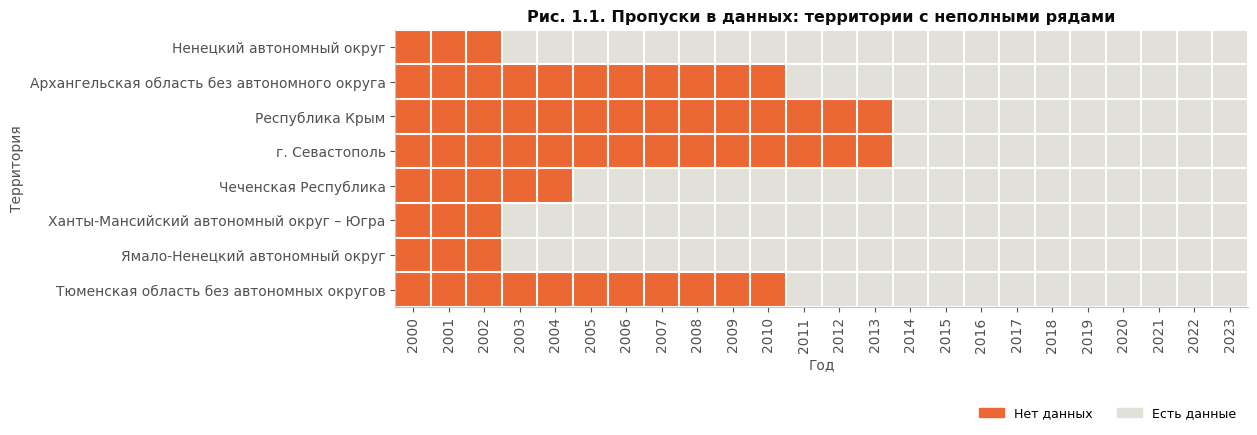

In [8]:
miss = df[df['n_missing'] > 0].set_index('region_name')[year_cols].isna()
print('Пропуски по годам (число территорий без данных):')
print(df[year_cols].isna().sum().loc[lambda s: s > 0].to_dict())

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.imshow(miss.values.astype(int), aspect='auto', cmap=ListedColormap([GRID, ORANGE]), interpolation='none')
ax.set_xticks(range(len(year_cols)), year_cols, rotation=90)
ax.set_yticks(range(len(miss)), miss.index)
ax.set_xticks(np.arange(-.5, len(year_cols)), minor=True)
ax.set_yticks(np.arange(-.5, len(miss)), minor=True)
ax.grid(which='minor', color='white', linewidth=1.5)
ax.grid(which='major', visible=False)
ax.tick_params(which='minor', length=0)
ax.set_title('Рис. 1.1. Пропуски в данных: территории с неполными рядами')
ax.set_xlabel('Год')
ax.set_ylabel('Территория')
ax.legend(handles=[Patch(color=ORANGE, label='Нет данных'), Patch(color=GRID, label='Есть данные')],
          loc='upper right', bbox_to_anchor=(1.0, -0.32), ncol=2)
save_fig(fig, '01_missing_heatmap')
plt.show()

## 1.5. Перевод из широкого формата в длинный и формирование рядов по регионам
Длинный формат «территория — год — значение» удобен для группировок и фильтров. После этого собираем словарь временных рядов
`series[регион]` (индекс — год) и матрицу `W` (строки — годы, столбцы — регионы), на которой строится весь дальнейший анализ.

In [9]:
long = df.melt(id_vars=['region_name', 'region_code', 'type'], value_vars=year_cols,
               var_name='year', value_name='consumption')
long['year'] = long['year'].astype(int)
print('Длинный формат:', long.shape, '= 96 территорий × 24 года')
display(long.sort_values(['region_name', 'year']).head(5))

# Отдельный временной ряд для каждого субъекта: индекс = год, значение = потребление на душу (руб.)
subjects = long[long['type'] == 'Субъект РФ']
series = {name: g.set_index('year')['consumption'].sort_index() for name, g in subjects.groupby('region_name')}
print(f'Сформировано рядов по субъектам: {len(series)}')
print('Пример, Курская область:', series['Курская область'].head(3).to_dict())

Длинный формат: (2304, 5) = 96 территорий × 24 года


,region_name,region_code,type,year,consumption
77,Алтайский край,1.000000e+09,Субъект РФ,2000,15751.1
173,Алтайский край,1.000000e+09,Субъект РФ,2001,21539.7
269,Алтайский край,1.000000e+09,Субъект РФ,2002,28855.5
365,Алтайский край,1.000000e+09,Субъект РФ,2003,35772.7
461,Алтайский край,1.000000e+09,Субъект РФ,2004,44268.9


Сформировано рядов по субъектам: 85
Пример, Курская область: {2000: 15690.0, 2001: 20964.7, 2002: 26421.6}


## 1.6. Исключение территорий
Правило: оставляем только **субъекты РФ** с **полным рядом 2000–2023**. Агрегаты (РФ, федеральные округа, «… без АО») исключаем,
потому что они дублируют данные субъектов. Субъекты с пропусками исключаем без восстановления, потому что пропущены
**начальные** отрезки длиной 3–14 лет и их интерполяция или экстраполяция была бы выдумыванием данных.

In [10]:
def missing_range(row):
    yrs = [int(y) for y in year_cols if pd.isna(row[y])]
    return f'{yrs[0]}–{yrs[-1]}' if yrs else '—'

context = {
    'Республика Крым': 'в составе РФ с 2014 г., данных за 2000–2013 гг. нет',
    'г. Севастополь': 'в составе РФ с 2014 г., данных за 2000–2013 гг. нет',
    'Ненецкий автономный округ': 'отдельный учёт АО начинается с 2003 г.; данные входят в строку «Архангельская область»',
    'Ханты-Мансийский автономный округ – Югра': 'отдельный учёт АО начинается с 2003 г.; данные входят в строку «Тюменская область»',
    'Ямало-Ненецкий автономный округ': 'отдельный учёт АО начинается с 2003 г.; данные входят в строку «Тюменская область»',
    'Чеченская Республика': 'данных за 2000–2004 гг. нет',
}
excl = df[(df['type'] != 'Субъект РФ') | (df['n_missing'] > 0)].copy()
excl['пропущенные годы'] = excl.apply(missing_range, axis=1)

def reason(r):
    if r['type'] == 'Россия в целом':
        return 'Агрегат по стране'
    if r['type'] == 'Федеральный округ':
        return 'Агрегат по федеральному округу'
    if r['type'] == 'Агрегат-дубль (без АО)':
        return f"Дублирующий агрегат «матрёшечного» субъекта; к тому же нет {r['n_missing']} лет"
    return f"Неполный ряд: нет {r['n_missing']} лет ({context.get(r['region_name'], '')})"

excl['причина исключения'] = excl.apply(reason, axis=1)
excluded = excl[['region_name', 'type', 'n_missing', 'пропущенные годы', 'причина исключения']].rename(
    columns={'region_name': 'территория', 'type': 'тип', 'n_missing': 'лет без данных'}).reset_index(drop=True)
save_tab(excluded, 'excluded_territories', index=False)
display(excluded)

full_subjects = [n for n, s in series.items() if s.notna().all()]
W = pd.DataFrame({n: series[n] for n in full_subjects}).astype(float)   # годы × регионы
rf = df.loc[df['type'] == 'Россия в целом', year_cols].iloc[0].astype(float)
rf.index = rf.index.astype(int)                                          # ряд по РФ: только для справки на графиках

print(f'Субъектов всего: {len(series)}; с полным рядом 2000–2023: {W.shape[1]}; '
      f'исключено субъектов с пропусками: {len(series) - W.shape[1]}')
RESULTS['n_records'] = int(raw.shape[0]); RESULTS['n_subjects'] = len(series); RESULTS['n_regions'] = int(W.shape[1])
RESULTS['excluded'] = excluded.to_dict(orient='records')

,территория,тип,лет без данных,пропущенные годы,причина исключения
0,Фактическое конечное потребление домашних хозяйств на территории субъектов Российской Федерации – всего,Россия в целом,0,—,Агрегат по стране
1,Центральный федеральный округ,Федеральный округ,0,—,Агрегат по федеральному округу
2,Северо-Западный федеральный округ,Федеральный округ,0,—,Агрегат по федеральному округу
3,Ненецкий автономный округ,Субъект РФ,3,2000–2002,Неполный ряд: нет 3 лет (отдельный учёт АО начинается с 2003 г.; данные входят в строку «Архангельская область»)
4,Архангельская область без автономного округа,Агрегат-дубль (без АО),11,2000–2010,Дублирующий агрегат «матрёшечного» субъекта; к тому же нет 11 лет
5,Южный федеральный округ,Федеральный округ,0,—,Агрегат по федеральному округу
6,Республика Крым,Субъект РФ,14,2000–2013,"Неполный ряд: нет 14 лет (в составе РФ с 2014 г., данных за 2000–2013 гг. нет)"
7,г. Севастополь,Субъект РФ,14,2000–2013,"Неполный ряд: нет 14 лет (в составе РФ с 2014 г., данных за 2000–2013 гг. нет)"
8,Северо-Кавказский федеральный округ,Федеральный округ,0,—,Агрегат по федеральному округу
9,Чеченская Республика,Субъект РФ,5,2000–2004,Неполный ряд: нет 5 лет (данных за 2000–2004 гг. нет)


Субъектов всего: 85; с полным рядом 2000–2023: 79; исключено субъектов с пропусками: 6


## 1.7. Проверка на аномальные значения
Даже в полных рядах возможны ошибки ввода. Поэтому ищем «выброс с возвратом»: рост больше 65% (Δln > 0.5) и сразу после него
падение больше 26% (Δln < −0.3). Для номинального потребления на душу такая пара скачков невозможна экономически.

In [11]:
dlogW = np.log(W).diff()
spikes = [(r, y) for r in W.columns for y in W.index[1:-1]
          if dlogW.loc[y, r] > 0.5 and dlogW.loc[y + 1, r] < -0.3]
print('Найдены выбросы с возвратом:', spikes)

ext = (W.pct_change() * 100).stack().rename('прирост, %').reset_index()
ext.columns = ['год', 'регион', 'прирост, %']
ext['медиана по регионам в этот год, %'] = ext['год'].map((W.pct_change() * 100).median(axis=1))
print('\nСамые экстремальные годовые изменения:')
display(pd.concat([ext.nlargest(4, 'прирост, %'), ext.nsmallest(4, 'прирост, %')]).round(1))

Найдены выбросы с возвратом: [('Красноярский край', 2004)]

Самые экстремальные годовые изменения:


,год,регион,"прирост, %","медиана по регионам в этот год, %"
260,2004,Красноярский край,208.0,26.9
154,2002,Чукотский автономный округ,70.9,29.9
75,2001,Чукотский автономный округ,69.8,33.4
90,2002,Забайкальский край,68.4,29.9
339,2005,Красноярский край,-53.3,26.6
651,2009,Кемеровская область,-9.4,9.1
701,2009,Тюменская область,-6.0,9.1
1563,2020,Свердловская область,-4.2,3.8


Красноярский край, 2004: 167,593.2 → 65,260.3 руб. (прирост +208% и затем -53%)


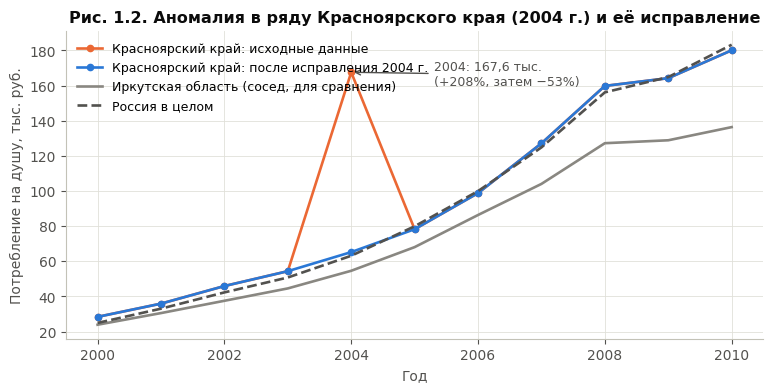

,"прирост 2002, %","прирост 2003, %","прирост 2004, %"
region_name,,,
Южный федеральный округ,29.2,-76.6,27.3
Северо-Кавказский федеральный округ,28.5,-80.6,33.1


In [12]:
IMPUTED = {}
W_raw = W.copy()
for r, y in spikes:
    # Одиночную ошибочную точку заменяем геометрическим средним соседей, то есть линейной интерполяцией в логарифмах.
    # Так сохраняется экспоненциальный характер роста. Это не восстановление длинного начального куска, а исправление одной точки.
    W.loc[y, r] = np.sqrt(W.loc[y - 1, r] * W.loc[y + 1, r])
    IMPUTED.setdefault(r, []).append(int(y))
    print(f'{r}, {y}: {W_raw.loc[y, r]:,.1f} → {W.loc[y, r]:,.1f} руб. '
          f'(прирост {W_raw.loc[y, r]/W_raw.loc[y-1, r]*100-100:+.0f}% и затем {W_raw.loc[y+1, r]/W_raw.loc[y, r]*100-100:+.0f}%)')
RESULTS['imputed'] = IMPUTED

fig, ax = plt.subplots(figsize=(9, 4))
yrs = range(2000, 2011)
r0 = spikes[0][0]
ax.plot(yrs, W_raw.loc[yrs, r0], color=ORANGE, marker='o', label=f'{r0}: исходные данные')
ax.plot(yrs, W.loc[yrs, r0], color=BLUE, marker='o', label=f'{r0}: после исправления 2004 г.')
ax.plot(yrs, W.loc[yrs, 'Иркутская область'], color=MUTED, label='Иркутская область (сосед, для сравнения)')
ax.plot(yrs, rf.loc[yrs], color=INK2, linestyle='--', label='Россия в целом')
ax.annotate('2004: 167,6 тыс.\n(+208%, затем −53%)', xy=(2004, W_raw.loc[2004, r0]), xytext=(2005.3, 160000),
            arrowprops=dict(arrowstyle='->', color=INK2), color=INK2, fontsize=9)
thousands(ax)
ax.set_title('Рис. 1.2. Аномалия в ряду Красноярского края (2004 г.) и её исправление')
ax.set_xlabel('Год')
ax.set_ylabel('Потребление на душу, тыс. руб.')
ax.legend(loc='upper left')
save_fig(fig, '02_anomaly_krasnoyarsk')
plt.show()

# Для справки: в агрегатах ЮФО и СКФО тоже есть разрыв методики (изменились границы округов), и это ещё одна причина
# не использовать агрегаты.
fo_check = df[df['region_name'].isin(['Южный федеральный округ', 'Северо-Кавказский федеральный округ'])].set_index('region_name')[['2001', '2002', '2003', '2004']]
display((fo_check.pct_change(axis=1) * 100).round(1).rename(columns=lambda c: f'прирост {c}, %').iloc[:, 1:])

**Итоги этапа 1.**
* Всего 96 записей: 1 по России в целом, 8 федеральных округов, 2 дублирующих агрегата «без АО» и 85 субъектов РФ.
* Пропуски есть у 8 территорий: «…» в 2000–2004 гг. и пустые ячейки в 2005–2013 гг. После 2014 г. пропусков нет.
* **Исключены 6 субъектов с неполными рядами:** Республика Крым и г. Севастополь (нет 14 лет, 2000–2013),
  Ненецкий, Ханты-Мансийский и Ямало-Ненецкий АО (нет 3 лет, 2000–2002), Чеченская Республика (нет 5 лет, 2000–2004).
  Кроме того, исключены все агрегаты: РФ, 8 ФО и 2 записи «… без АО». Полный перечень с причинами приведён в таблице выше
  (`tables/excluded_territories.csv`).
* Архангельская и Тюменская области оставлены в «полном» составе (с АО). Сами АО исключены из-за пропусков, поэтому двойного счёта нет.
* Исправлены три дефекта данных: латинская «p» в названии Калининградской области, её пустой код ОКАТО и ошибочное значение
  Красноярского края за 2004 г. (167,6 тыс. руб. при соседних 54,4 и 78,3 тыс.), которое заменено геометрическим средним соседей (65,3 тыс.).
* **В анализ вошли 79 регионов с полными рядами за 24 года.**

---
# Этап 2. Кластерный анализ регионов
## 2.1. Признаки временных рядов
Данные в текущих ценах, поэтому абсолютный уровень отражает в основном масштаб доходов региона и общую инфляцию.
Чтобы группировать регионы по **характеру динамики**, большинство признаков берём относительные (безразмерные):

| Признак | Формула | Что характеризует |
|---|---|---|
| `log_mean` | ln(среднее за 2000–2023) | общий уровень потребления; логарифм гасит экстремальный уровень Москвы |
| `cv` | σ / среднее | относительный разброс ряда, не зависящий от масштаба |
| `cagr` | (y₂₀₂₃ / y₂₀₀₀)^(1/23) − 1 | средний годовой темп роста |
| `rel_change` | y₂₀₂₃ / y₂₀₀₀ | относительное изменение за период |
| `max_drop` | min годового темпа прироста | максимальное годовое падение (если спадов не было, то наименьший прирост) |
| `neg_share` | доля лет с yₜ < yₜ₋₁ | частота спадов |
| `growth_vol` | σ годовых темпов прироста | волатильность динамики (для справки) |

In [13]:
def extract_features(s: pd.Series) -> pd.Series:
    g = s.pct_change().dropna()                       # годовые темпы прироста
    return pd.Series({
        'mean_level': s.mean(),
        'cv': s.std() / s.mean(),
        'cagr': (s.iloc[-1] / s.iloc[0]) ** (1 / (len(s) - 1)) - 1,
        'rel_change': s.iloc[-1] / s.iloc[0],
        'max_drop': g.min(),
        'neg_share': (g < 0).mean(),
        'growth_vol': g.std(),
    })

feats = W.apply(extract_features).T
feats.insert(1, 'log_mean', np.log(feats['mean_level']))
desc = feats.describe().T[['mean', 'std', 'min', '50%', 'max']]
display(desc.round(4))
print('Регионов хотя бы с одним годом номинального спада:', int((feats['neg_share'] > 0).sum()), 'из', len(feats))
print('Годы спадов и сколько регионов падало:', (W.pct_change() < 0).sum(axis=1).loc[lambda s: s > 0].to_dict())

,mean,std,min,50%,max
mean_level,209967.3809,65290.1575,75110.6125,191444.6667,504230.9375
log_mean,12.2129,0.2870,11.2267,12.1624,13.1308
cv,0.7137,0.0484,0.5818,0.7163,0.8190
cagr,0.1555,0.0110,0.1132,0.1571,0.1867
rel_change,28.3623,5.9536,11.7724,28.6755,51.3104
max_drop,0.0144,0.0289,-0.0936,0.0163,0.0669
neg_share,0.0110,0.0203,0.0000,0.0000,0.0870
growth_vol,0.1028,0.0199,0.0701,0.0989,0.1830


Регионов хотя бы с одним годом номинального спада: 19 из 79
Годы спадов и сколько регионов падало: {2009: 4, 2010: 1, 2015: 5, 2018: 1, 2019: 3, 2020: 6}


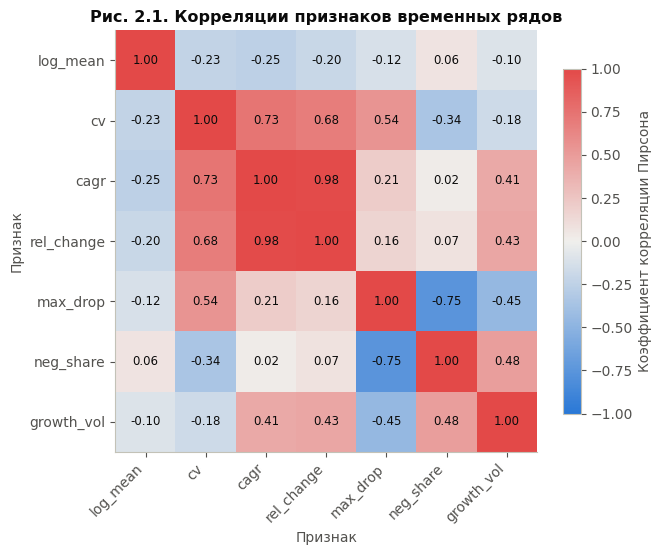

In [14]:
corr = feats[['log_mean', 'cv', 'cagr', 'rel_change', 'max_drop', 'neg_share', 'growth_vol']].corr()
div_cmap = LinearSegmentedColormap.from_list('div', [BLUE, BAND, '#e34948'])   # синий ↔ серый ↔ красный
fig, ax = plt.subplots(figsize=(6.8, 5.6))
im = ax.imshow(corr.values, cmap=div_cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr)), corr.index)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', fontsize=8.5, color=INK)
fig.colorbar(im, ax=ax, shrink=0.8, label='Коэффициент корреляции Пирсона')
ax.set_title('Рис. 2.1. Корреляции признаков временных рядов')
ax.set_xlabel('Признак')
ax.set_ylabel('Признак')
save_fig(fig, '03_feature_corr')
plt.show()

**Выбор признаков для кластеризации.** Берём пять признаков из рекомендованного списка: `log_mean`, `cv`, `cagr`, `max_drop`, `neg_share`.
Четыре из них относительные и характеризуют динамику.
* `rel_change` не включаем: это монотонное преобразование `cagr` (корреляция 0,98), он удвоил бы вес темпа роста.
* `growth_vol` не включаем: он сильно связан с `max_drop` (|r| ≈ 0,45) и почти целиком определяется теми же кризисными годами.
* Средний уровень берём в логарифме, потому что распределение скошено: Москва (504 тыс. руб.) в 2,6 раза выше медианы (191 тыс.).
  Без логарифма Москва после стандартизации стала бы отдельным кластером «по уровню», а не по динамике.
* `cv` коррелирует с `cagr` (0,73), но несёт свою информацию: в номинальном ряду он выше там, где рост сильнее смещён к концу периода.

## 2.2. Стандартизация

In [15]:
FEATURES = ['log_mean', 'cv', 'cagr', 'max_drop', 'neg_share']
scaler = StandardScaler()
X = scaler.fit_transform(feats[FEATURES])     # z-оценки: среднее 0, ст. отклонение 1
print('Средние после стандартизации:', X.mean(axis=0).round(6))
print('Ст. отклонения после стандартизации:', X.std(axis=0).round(6))

Средние после стандартизации: [ 0. -0.  0.  0.  0.]
Ст. отклонения после стандартизации: [1. 1. 1. 1. 1.]


Стандартизация нужна, потому что K-means считает евклидовы расстояния. Без неё признаки в разных единицах получили бы
несопоставимые веса: `log_mean` около 12, а `neg_share` от 0 до 0,09.

## 2.3. Выбор алгоритма и числа кластеров
**Алгоритм: K-means.** Он подходит для непрерывных стандартизованных признаков и небольшой выборки (79 объектов).
Центроиды K-means прямо читаются как «типичный профиль» группы, а расстояние до центроида пригодится на этапе 3 для выбора
представителя. Используем `n_init=50`, чтобы не застрять в локальном минимуме, и фиксированный `random_state` для воспроизводимости.
**Для проверки устойчивости** сравниваем разбиение с агломеративной кластеризацией Уорда (иерархический метод с тем же критерием
минимума внутрикластерной дисперсии) по индексу ARI.

In [16]:
rows, labels_by_k, profiles = [], {}, {}
for k in [2, 3, 4]:
    km_k = KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE).fit(X)
    ward_k = AgglomerativeClustering(n_clusters=k, linkage='ward').fit(X)
    labels_by_k[k] = km_k.labels_
    rows.append({'k': k,
                 'silhouette (K-means)': silhouette_score(X, km_k.labels_),
                 'silhouette (Ward)': silhouette_score(X, ward_k.labels_),
                 'ARI K-means vs Ward': adjusted_rand_score(km_k.labels_, ward_k.labels_),
                 'inertia': km_k.inertia_,
                 'размеры кластеров': sorted(np.bincount(km_k.labels_).tolist(), reverse=True)})
    prof = feats.assign(cl=km_k.labels_).groupby('cl').agg(
        n=('cagr', 'size'), mean_level_k=('mean_level', lambda s: s.mean() / 1000), cagr_pct=('cagr', lambda s: s.mean() * 100),
        cv=('cv', 'mean'), max_drop_pct=('max_drop', lambda s: s.mean() * 100), neg_share_pct=('neg_share', lambda s: s.mean() * 100))
    profiles[k] = prof
k_table = pd.DataFrame(rows).set_index('k')
save_tab(k_table.drop(columns='размеры кластеров'), 'k_selection')
display(k_table.round(3))
RESULTS['silhouette'] = {int(k): float(v) for k, v in k_table['silhouette (K-means)'].items()}
RESULTS['silhouette_ward'] = {int(k): float(v) for k, v in k_table['silhouette (Ward)'].items()}
RESULTS['ari'] = {int(k): float(v) for k, v in k_table['ARI K-means vs Ward'].items()}

for k in [2, 3, 4]:
    print(f'\nПрофили кластеров при k={k} (средние: уровень в тыс. руб., темпы и доли в %):')
    display(profiles[k].round(2))

,silhouette (K-means),silhouette (Ward),ARI K-means vs Ward,inertia,размеры кластеров
k,,,,,
2,0.406,0.413,0.947,259.582,"[58, 21]"
3,0.321,0.368,0.539,205.105,"[45, 18, 16]"
4,0.268,0.259,0.533,169.151,"[31, 28, 14, 6]"



Профили кластеров при k=2 (средние: уровень в тыс. руб., темпы и доли в %):


,n,mean_level_k,cagr_pct,cv,max_drop_pct,neg_share_pct
cl,,,,,,
0,21,232.66,15.17,0.68,-2.17,4.14
1,58,201.75,15.68,0.73,2.75,0.00



Профили кластеров при k=3 (средние: уровень в тыс. руб., темпы и доли в %):


,n,mean_level_k,cagr_pct,cv,max_drop_pct,neg_share_pct
cl,,,,,,
0,45,198.20,16.01,0.74,3.08,0.00
1,16,235.81,14.20,0.67,1.18,0.27
2,18,216.41,15.58,0.69,-2.44,4.59



Профили кластеров при k=4 (средние: уровень в тыс. руб., темпы и доли в %):


,n,mean_level_k,cagr_pct,cv,max_drop_pct,neg_share_pct
cl,,,,,,
0,14,205.26,16.01,0.70,-1.83,4.66
1,31,210.22,16.25,0.75,3.35,0.00
2,28,194.28,15.00,0.70,1.98,0.00
3,6,292.89,13.37,0.62,-3.36,3.62


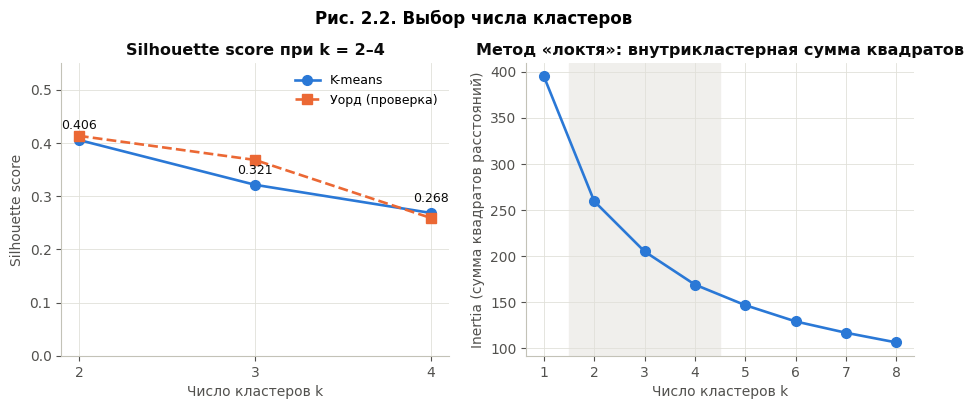

In [17]:
inertias = [KMeans(n_clusters=k, n_init=50, random_state=RANDOM_STATE).fit(X).inertia_ for k in range(1, 9)]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ks = k_table.index.values
ax.plot(ks, k_table['silhouette (K-means)'], color=BLUE, marker='o', markersize=7, label='K-means')
ax.plot(ks, k_table['silhouette (Ward)'], color=ORANGE, marker='s', markersize=7, linestyle='--', label='Уорд (проверка)')
for k, v in zip(ks, k_table['silhouette (K-means)']):
    ax.annotate(f'{v:.3f}', (k, v), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9, color=INK)
ax.set_xticks(ks)
ax.set_ylim(0, 0.55)
ax.set_title('Silhouette score при k = 2–4')
ax.set_xlabel('Число кластеров k')
ax.set_ylabel('Silhouette score')
ax.legend()
ax = axes[1]
ax.plot(range(1, 9), inertias, color=BLUE, marker='o', markersize=7)
ax.axvspan(1.5, 4.5, color=BAND, zorder=0)
ax.set_title('Метод «локтя»: внутрикластерная сумма квадратов')
ax.set_xlabel('Число кластеров k')
ax.set_ylabel('Inertia (сумма квадратов расстояний)')
fig.suptitle('Рис. 2.2. Выбор числа кластеров', fontweight='bold', y=1.02)
save_fig(fig, '04_k_selection')
plt.show()

**Выбор k = 3.**
* **k = 2** даёт наибольший силуэт (≈0,41), но делит регионы только по одному признаку: были ли годы номинального спада.
  В одну группу попадают Москва (самый низкий темп роста, 11,3% в год) и Краснодарский край (один из самых высоких, 17,5%),
  то есть различие в скорости роста теряется.
* **k = 3** (силуэт ≈0,32) дополнительно отделяет группу с **замедленным ростом** (≈14,2% против ≈16,0% в год) и пониженным CV.
  Это экономически осмысленное разделение: регионы с высокой стартовой базой растут медленнее, то есть идёт межрегиональная конвергенция.
  Все три группы легко интерпретировать, ни одна не вырождена (размеры 45 / 18 / 16).
* **k = 4** снижает силуэт до ≈0,27 и выделяет маленькую группу из 6 регионов, а «устойчивые» регионы делит на две части
  с близкими темпами роста (16,3% и 15,0%). Такая граница слабее и хуже интерпретируется.

Значения силуэта 0,3–0,4 говорят об умеренно выраженной структуре: регионы образуют скорее континуум, и кластеры полезны как
**типология**, а не как жёстко разделённые группы. Это подтверждает и умеренное согласие K-means с методом Уорда при k = 3 (ARI ≈0,5).
Поэтому выбираем **k = 3** как компромисс между метрикой и содержательной интерпретацией. Кроме того, при k = 3 из каждой группы
берётся ровно по одному представителю.

## 2.4. Итоговая кластеризация (k = 3) и описание кластеров

In [18]:
K = 3
km = KMeans(n_clusters=K, n_init=50, random_state=RANDOM_STATE).fit(X)

# Номера кластеров у K-means произвольны, поэтому назначаем имена по профилю, а не по номеру:
#   кластер с наибольшей долей лет спада → «рост с эпизодами спада»;
#   из оставшихся: меньший CAGR → «замедленный рост», больший → «устойчивый быстрый рост».
prof = feats.assign(cl=km.labels_).groupby('cl')[FEATURES].mean()
c_decl = prof['neg_share'].idxmax()
rest = prof.drop(c_decl)
c_slow, c_fast = rest['cagr'].idxmin(), rest['cagr'].idxmax()
ORDER = {c_fast: 1, c_decl: 2, c_slow: 3}
CLUSTER_NAMES = {1: 'Устойчивый быстрый рост', 2: 'Рост с эпизодами спада', 3: 'Замедленный рост с высокой базы'}
feats['cluster'] = [ORDER[c] for c in km.labels_]
feats['cluster_name'] = feats['cluster'].map(CLUSTER_NAMES)
centroids = pd.DataFrame(km.cluster_centers_, columns=FEATURES).rename(index=ORDER).sort_index()

ratio_rf = W.div(rf, axis=0)   # уровень региона относительно среднего по РФ (в один год цены сопоставимы)
summary = feats.groupby('cluster').agg(
    n=('cagr', 'size'),
    level_2000=('cagr', lambda s: W.loc[2000, s.index].mean() / 1000),
    level_2023=('cagr', lambda s: W.loc[2023, s.index].mean() / 1000),
    ratio_rf_2000=('cagr', lambda s: ratio_rf.loc[2000, s.index].mean()),
    ratio_rf_2023=('cagr', lambda s: ratio_rf.loc[2023, s.index].mean()),
    mean_level=('mean_level', lambda s: s.mean() / 1000),
    cagr_pct=('cagr', lambda s: s.mean() * 100),
    cv=('cv', 'mean'),
    max_drop_pct=('max_drop', lambda s: s.mean() * 100),
    neg_share_pct=('neg_share', lambda s: s.mean() * 100),
    with_decline=('neg_share', lambda s: int((s > 0).sum())),
    growth_vol_pct=('growth_vol', lambda s: s.mean() * 100),
)
summary.insert(0, 'название', summary.index.map(CLUSTER_NAMES))
summary.columns = ['название', 'регионов', 'уровень 2000, тыс. руб.', 'уровень 2023, тыс. руб.', 'к РФ в 2000', 'к РФ в 2023',
                   'среднее за период, тыс. руб.', 'CAGR, %', 'CV', 'макс. падение, %', 'доля лет спада, %',
                   'регионов со спадом', 'волатильность темпов, п.п.']
save_tab(summary, 'cluster_summary')
display(summary.round(3))

members = feats.sort_values(['cluster', 'cagr'], ascending=[True, False]).groupby('cluster').apply(lambda d: ', '.join(d.index))
members_df = pd.DataFrame({'кластер': [CLUSTER_NAMES[c] for c in members.index], 'регионы': members.values})
save_tab(members_df, 'cluster_members', index=False)
for c, txt in members.items():
    print(f'\nКластер {c}: «{CLUSTER_NAMES[c]}» ({(feats.cluster == c).sum()} регионов):\n{txt}')

decl_years = {c: (W[feats.index[feats.cluster == c]].pct_change() < 0).sum(axis=1).loc[lambda s: s > 0].to_dict() for c in [1, 2, 3]}
print('\nГоды номинального спада (число регионов) по кластерам:', decl_years)
RESULTS['cluster_summary'] = summary.reset_index().to_dict(orient='records')
RESULTS['decline_years_by_cluster'] = decl_years
feats.round(5).to_csv(TAB_DIR / 'region_features.csv', encoding='utf-8-sig')

,название,регионов,"уровень 2000, тыс. руб.","уровень 2023, тыс. руб.",к РФ в 2000,к РФ в 2023,"среднее за период, тыс. руб.","CAGR, %",CV,"макс. падение, %","доля лет спада, %",регионов со спадом,"волатильность темпов, п.п."
cluster,,,,,,,,,,,,,
1,Устойчивый быстрый рост,45,16.919,516.471,0.678,0.853,198.202,16.011,0.741,3.082,0.000,0,9.994
2,Рост с эпизодами спада,18,19.595,524.562,0.785,0.867,216.409,15.582,0.687,-2.436,4.589,18,11.955
3,Замедленный рост с высокой базы,16,28.705,569.067,1.150,0.940,235.811,14.195,0.667,1.177,0.272,1,9.183



Кластер 1: «Устойчивый быстрый рост» (45 регионов):
Краснодарский край, Ивановская область, Республика Алтай, Брянская область, Московская область, Тульская область, Владимирская область, Сахалинская область, Нижегородская область, Ленинградская область, Республика Адыгея, Тверская область, Рязанская область, г. Санкт-Петербург, Республика Татарстан, Калужская область, Чувашская Республика, Архангельская область, Республика Тыва, Республика Ингушетия, Кабардино-Балкарская Республика, Курская область, Псковская область, Еврейская автономная область, Амурская область, Ярославская область, Оренбургская область, Республика Карелия, Пензенская область, Республика Мордовия, Волгоградская область, Костромская область, Магаданская область, Республика Северная Осетия – Алания, Орловская область, Кировская область, Ульяновская область, Республика Бурятия, Белгородская область, Республика Марий Эл, Удмуртская Республика, Липецкая область, Республика Хакасия, Саратовская область, Калининградская 

Доля объяснённой дисперсии: [0.479 0.269] | нагрузки:


,PC1,PC2
log_mean,-0.23,-0.35
cv,0.56,0.25
cagr,0.41,0.58
max_drop,0.53,-0.39
neg_share,-0.43,0.58


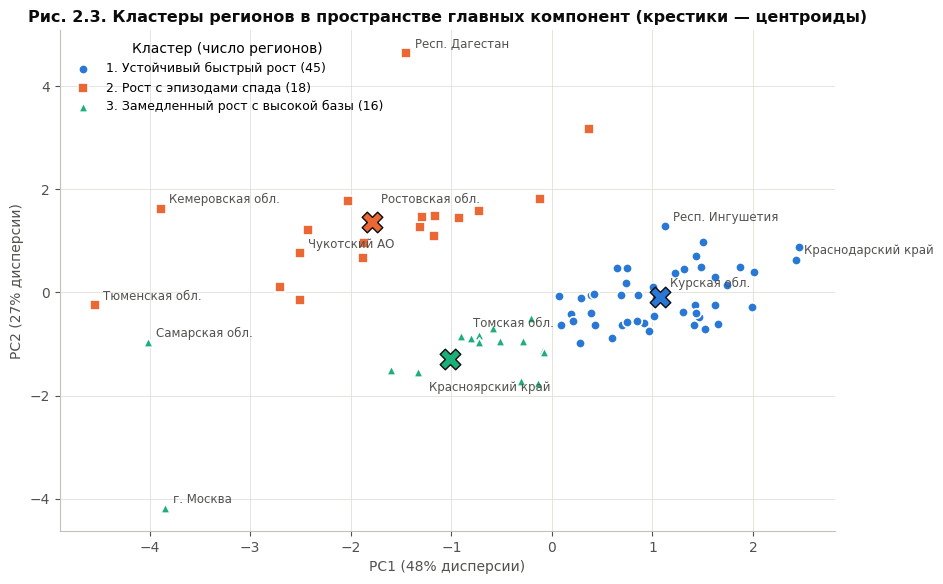

In [19]:
# Визуализация в пространстве двух главных компонент: это только проекция 5 признаков на плоскость для наглядности.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(X)
load = pd.DataFrame(pca.components_.T, index=FEATURES, columns=['PC1', 'PC2'])
print('Доля объяснённой дисперсии:', pca.explained_variance_ratio_.round(3), '| нагрузки:')
display(load.round(2))

fig, ax = plt.subplots(figsize=(10, 6.5))
for c in [1, 2, 3]:
    m = feats['cluster'].values == c
    ax.scatter(Z[m, 0], Z[m, 1], s=46, color=CLUSTER_COLORS[c], marker=CLUSTER_MARKERS[c],
               edgecolor='white', linewidth=1.2, label=f'{c}. {CLUSTER_NAMES[c]} ({m.sum()})', zorder=3)
cz = pca.transform(km.cluster_centers_)
for raw_c, ordc in ORDER.items():
    ax.scatter(*cz[raw_c], s=220, marker='X', color=CLUSTER_COLORS[ordc], edgecolor=INK, linewidth=1, zorder=4)
to_label = ['г. Москва', 'Республика Дагестан', 'Кемеровская область', 'Тюменская область', 'Краснодарский край',
            'Республика Ингушетия', 'Чукотский автономный округ', 'Курская область', 'Ростовская область',
            'Томская область', 'Красноярский край', 'Самарская область']
offsets = {'Красноярский край': (8, -14), 'Курская область': (10, 8), 'Томская область': (-20, 10),
           'Ростовская область': (-30, 10)}
for name in to_label:
    i = feats.index.get_loc(name)
    ax.annotate(name.replace('Республика', 'Респ.').replace('область', 'обл.').replace('автономный округ', 'АО'),
                (Z[i, 0], Z[i, 1]), textcoords='offset points', xytext=offsets.get(name, (6, 4)), fontsize=8.5, color=INK2)
ax.set_title('Рис. 2.3. Кластеры регионов в пространстве главных компонент (крестики — центроиды)')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.0f}% дисперсии)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.0f}% дисперсии)')
ax.legend(title='Кластер (число регионов)', loc='best')
save_fig(fig, '05_clusters_pca')
plt.show()

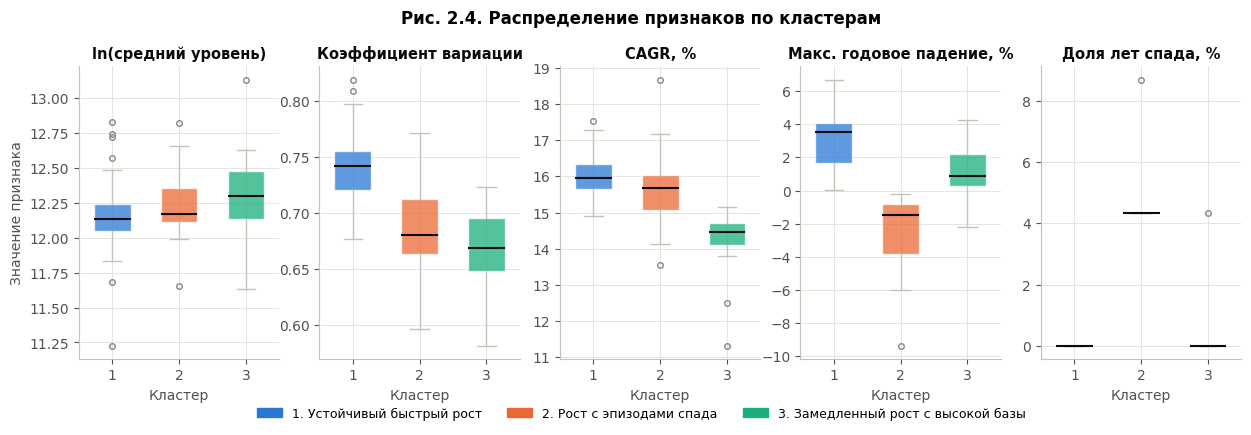

In [20]:
labels_ru = {'log_mean': 'ln(средний уровень)', 'cv': 'Коэффициент вариации', 'cagr': 'CAGR, %',
             'max_drop': 'Макс. годовое падение, %', 'neg_share': 'Доля лет спада, %'}
scale = {'log_mean': 1, 'cv': 1, 'cagr': 100, 'max_drop': 100, 'neg_share': 100}
fig, axes = plt.subplots(1, 5, figsize=(15, 3.8))
for ax, f in zip(axes, FEATURES):
    data = [feats.loc[feats.cluster == c, f] * scale[f] for c in [1, 2, 3]]
    bp = ax.boxplot(data, patch_artist=True, widths=0.55, medianprops=dict(color=INK, linewidth=1.5),
                    whiskerprops=dict(color=AXIS), capprops=dict(color=AXIS), flierprops=dict(markeredgecolor=MUTED, markersize=4))
    for patch, c in zip(bp['boxes'], [1, 2, 3]):
        patch.set_facecolor(CLUSTER_COLORS[c]); patch.set_alpha(0.75); patch.set_edgecolor('white')
    ax.set_xticks([1, 2, 3], ['1', '2', '3'])
    ax.set_title(labels_ru[f], fontsize=10.5)
    ax.set_xlabel('Кластер')
axes[0].set_ylabel('Значение признака')
fig.legend(handles=[Patch(color=CLUSTER_COLORS[c], label=f'{c}. {CLUSTER_NAMES[c]}') for c in [1, 2, 3]],
           loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.08))
fig.suptitle('Рис. 2.4. Распределение признаков по кластерам', fontweight='bold', y=1.03)
save_fig(fig, '06_cluster_boxplots')
plt.show()

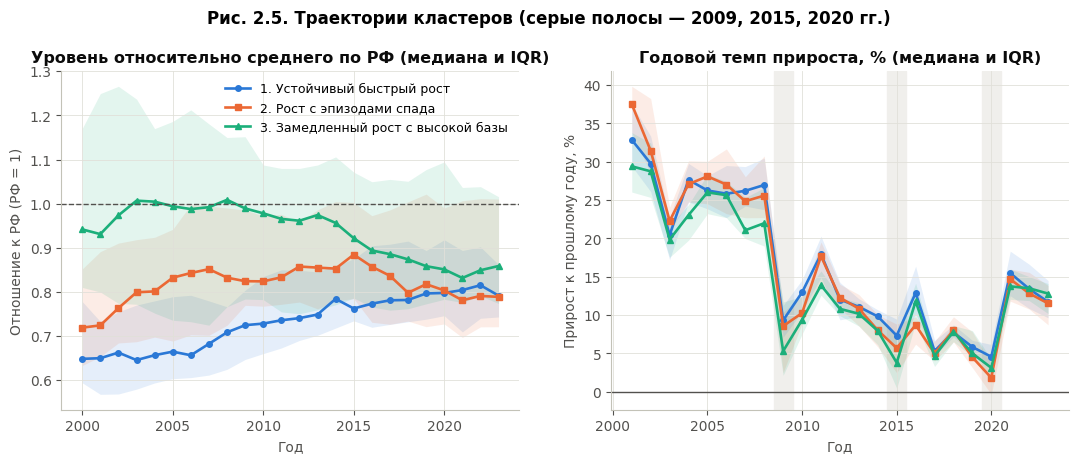

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
growth = W.pct_change() * 100
for c in [1, 2, 3]:
    cols = feats.index[feats.cluster == c]
    for ax, data in [(axes[0], ratio_rf[cols]), (axes[1], growth[cols])]:
        med = data.median(axis=1)
        q1, q3 = data.quantile(0.25, axis=1), data.quantile(0.75, axis=1)
        ax.fill_between(data.index, q1, q3, color=CLUSTER_COLORS[c], alpha=0.12, linewidth=0)
        ax.plot(data.index, med, color=CLUSTER_COLORS[c], marker=CLUSTER_MARKERS[c], markersize=4, label=f'{c}. {CLUSTER_NAMES[c]}')
axes[0].axhline(1, color=INK2, linestyle='--', linewidth=1)
axes[0].set_title('Уровень относительно среднего по РФ (медиана и IQR)')
axes[0].set_ylabel('Отношение к РФ (РФ = 1)')
axes[1].axhline(0, color=INK2, linewidth=1)
for y in (2009, 2015, 2020):
    axes[1].axvspan(y - 0.5, y + 0.5, color=BAND, zorder=0)
axes[1].set_title('Годовой темп прироста, % (медиана и IQR)')
axes[1].set_ylabel('Прирост к прошлому году, %')
for ax in axes:
    ax.set_xlabel('Год')
axes[0].legend(loc='upper right')
fig.suptitle('Рис. 2.5. Траектории кластеров (серые полосы — 2009, 2015, 2020 гг.)', fontweight='bold', y=1.02)
save_fig(fig, '07_cluster_trajectories')
plt.show()

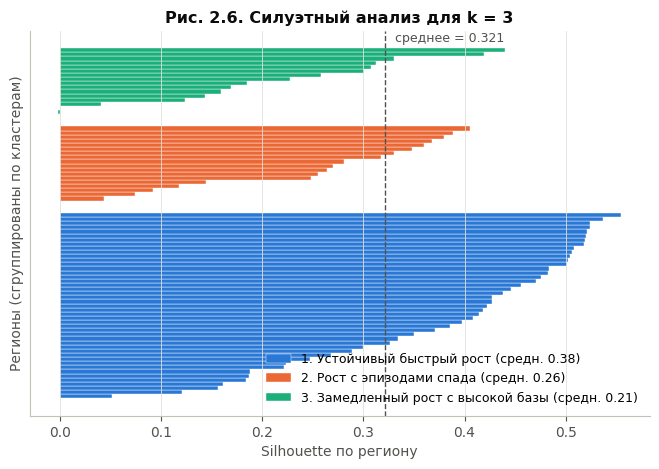

Регионы с отрицательным силуэтом (пограничные): ['Самарская область']


In [22]:
sil = silhouette_samples(X, feats['cluster'].values)
fig, ax = plt.subplots(figsize=(8, 5))
y0 = 0
for c in [1, 2, 3]:
    v = np.sort(sil[feats['cluster'].values == c])
    ax.barh(np.arange(y0, y0 + len(v)), v, height=1.0, color=CLUSTER_COLORS[c], edgecolor='white', linewidth=0.3,
            label=f'{c}. {CLUSTER_NAMES[c]} (средн. {v.mean():.2f})')
    y0 += len(v) + 3
ax.axvline(sil.mean(), color=INK2, linestyle='--', linewidth=1)
ax.text(sil.mean() + 0.01, y0 - 2, f'среднее = {sil.mean():.3f}', color=INK2, fontsize=9)
ax.set_yticks([])
ax.set_title('Рис. 2.6. Силуэтный анализ для k = 3')
ax.set_xlabel('Silhouette по региону')
ax.set_ylabel('Регионы (сгруппированы по кластерам)')
ax.legend(loc='lower right')
save_fig(fig, '08_silhouette_k3')
plt.show()
print('Регионы с отрицательным силуэтом (пограничные):', list(feats.index[sil < 0]))

**Описание кластеров** (числа взяты из таблицы `cluster_summary` и рис. 2.4–2.5):

1. **«Устойчивый быстрый рост» (45 регионов)**: большинство регионов Центральной России, Поволжья и Северного Кавказа,
   а также Санкт-Петербург, Татарстан и Краснодарский край. Средний темп роста самый высокий, около 16,0% в год, и **ни в одном
   году не было номинального спада** (доля лет спада 0%, наименьший прирост в среднем около +3%). Коэффициент вариации максимальный
   (около 0,74), потому что рост сильнее смещён к концу периода. Средний уровень в 2023 г. около 516 тыс. руб. на человека.
2. **«Рост с эпизодами спада» (18 регионов)**: индустриальные и ресурсные регионы (Свердловская, Челябинская, Кемеровская,
   Тюменская области, Пермский край, Якутия, Чукотка), а также ряд аграрных регионов Юга (Ростовская, Воронежская, Тамбовская
   области, Ставропольский край, Дагестан, Калмыкия). Средний темп роста около 15,6%, но **во всех 18 регионах был хотя бы один год
   номинального падения** (наибольшее падение в среднем −2,4%). Спады приходятся на кризисные годы: 2009 (4 региона),
   2015 (4), 2019–2020 (3 и 6). 2009 г. — финансовый кризис, 2015 г. — нефтяной шок и девальвация, 2020 г. — пандемия.
   Волатильность темпов в этой группе наибольшая (около 12,0 п.п. против 9–10). Это группа, чувствительная к шокам.
3. **«Замедленный рост с высокой базы» (16 регионов)**: Москва, северные и сибирские регионы (Коми, Мурманская область,
   Красноярский край, Иркутская, Новосибирская, Томская области), Дальний Восток (Камчатка, Хабаровский край), Самарская область,
   Башкортостан и др. Темп роста самый низкий, около 14,2%, CV самый низкий (около 0,67), спад был только у одного региона
   (Самарская область, 2015 г.). В 2000 г. эти регионы в среднем стояли выше среднероссийского уровня (отношение к РФ 1,15,
   медиана 0,94), а к 2023 г. опустились до 0,94 (медиана около 0,86). Кластеры 1 и 2, наоборот, поднялись (0,68 → 0,85 и
   0,79 → 0,87). Это проявление **конвергенции**: богатые на старте регионы растут медленнее.

Пограничные регионы с отрицательным силуэтом перечислены выше. Это ещё раз показывает, что границы между типами размыты.

---
# Этап 3. Выбор регионов для детального прогнозирования
Правило выбора: из каждого кластера берём регион, **ближайший к центроиду** в стандартизованном пространстве признаков.
Такой регион по построению репрезентативен: его профиль ближе всего к среднему профилю группы.
Дополнительное требование: ряд не должен содержать исправленных нами значений, чтобы прогноз строился на исходных данных Росстата.

In [23]:
raw_centers = km.cluster_centers_[km.labels_]
feats['dist_to_centroid'] = np.linalg.norm(X - raw_centers, axis=1)
closest = (feats.sort_values('dist_to_centroid').groupby('cluster').head(4)
           .sort_values(['cluster', 'dist_to_centroid']))
show = closest[['cluster', 'dist_to_centroid', 'mean_level', 'cv', 'cagr', 'max_drop', 'neg_share']].copy()
show['mean_level'] /= 1000
display(show.round(3))
print('Средние расстояния до центроида по кластерам:', feats.groupby('cluster')['dist_to_centroid'].mean().round(3).to_dict())

SELECTED = {}
for c in [1, 2, 3]:
    cand = feats[(feats.cluster == c) & (~feats.index.isin(IMPUTED.keys()))].sort_values('dist_to_centroid')
    SELECTED[c] = cand.index[0]
REGIONS = [SELECTED[c] for c in [1, 2, 3]]
REGION_COLOR = {SELECTED[c]: CLUSTER_COLORS[c] for c in [1, 2, 3]}
REGION_CLUSTER = {SELECTED[c]: c for c in [1, 2, 3]}
print('\nВыбранные регионы:', SELECTED)
RESULTS['selected'] = {int(c): r for c, r in SELECTED.items()}
RESULTS['closest_table'] = show.reset_index().rename(columns={'index': 'region'}).to_dict(orient='records')

,cluster,dist_to_centroid,mean_level,cv,cagr,max_drop,neg_share
Курская область,1,0.091,190.929,0.737,0.160,0.031,0.000
Тверская область,1,0.392,192.903,0.734,0.163,0.026,0.000
Оренбургская область,1,0.406,178.194,0.733,0.158,0.024,0.000
Ярославская область,1,0.528,199.438,0.747,0.159,0.044,0.000
Ростовская область,2,0.654,218.896,0.714,0.158,-0.020,0.043
Ставропольский край,2,0.814,184.669,0.669,0.151,-0.015,0.043
Забайкальский край,2,0.920,180.944,0.683,0.161,-0.007,0.043
Алтайский край,2,0.987,166.038,0.694,0.153,-0.010,0.043
Красноярский край,3,0.485,227.939,0.659,0.138,0.005,0.000
Томская область,3,0.706,191.445,0.678,0.146,0.014,0.000


Средние расстояния до центроида по кластерам: {1: 1.25, 2: 1.718, 3: 1.499}

Выбранные регионы: {1: 'Курская область', 2: 'Ростовская область', 3: 'Томская область'}


**Обоснование выбора:**
* **Кластер 1 → Курская область.** Расстояние до центроида 0,09, это самый «типичный» регион всей выборки. Её профиль почти
  совпадает со средним по кластеру: CAGR 16,0%, CV 0,74, ни одного года спада.
* **Кластер 2 → Ростовская область.** Ближайший к центроиду регион своего кластера (0,65). Как и у всей группы, рост 15,8%
  в год сочетается с номинальным спадом в 2009 г. (−2,0%). Это крупный многоотраслевой регион юга (промышленность, АПК,
  логистика), то есть типичный представитель «чувствительных к шокам».
* **Кластер 3 → Томская область.** Формально ближе всего к центроиду Красноярский край (0,49), но в его ряду мы исправили
  значение 2004 г. Следующий по близости регион, Томская область (0,71), заметно ближе к центроиду, чем в среднем регионы
  кластера (1,50). У неё типичный для группы профиль: относительно высокий уровень, замедленный рост 14,6% в год, низкий CV и
  отсутствие спадов. Это ресурсный регион (нефть и газ) с крупным научно-образовательным сектором.

Три региона представляют три разных типа динамики, поэтому сравнение моделей между ними содержательно.

### Базовая статистика выбранных регионов

In [24]:
def basic_stats(s):
    years = s.index.values.astype(float)
    lr = stats.linregress(years, s.values)               # линейный тренд: руб. в год
    lr_log = stats.linregress(years, np.log(s.values))   # лог-линейный тренд: средний экспоненциальный темп
    return pd.Series({
        'среднее, руб.': s.mean(), 'минимум, руб.': s.min(), 'год минимума': s.idxmin(),
        'максимум, руб.': s.max(), 'год максимума': s.idxmax(),
        'наклон тренда, руб./год': lr.slope, 'ст. ошибка наклона': lr.stderr, 'p-value наклона': lr.pvalue,
        'R² линейного тренда': lr.rvalue ** 2,
        'R² лог-линейного тренда': lr_log.rvalue ** 2, 'темп по лог-тренду, %/год': (np.exp(lr_log.slope) - 1) * 100,
        'CAGR 2000–2023, %': feats.loc[s.name, 'cagr'] * 100, 'CV': feats.loc[s.name, 'cv'],
        'к РФ в 2023': s.loc[2023] / rf.loc[2023],
    })

base = pd.DataFrame({r: basic_stats(W[r].rename(r)) for r in REGIONS})
save_tab(base, 'selected_basic_stats')
display(base.round(3))
RESULTS['basic_stats'] = base.to_dict()

,Курская область,Ростовская область,Томская область
"среднее, руб.",190928.508,218896.179,191444.667
"минимум, руб.",15690.000,19255.700,21459.000
год минимума,2000.000,2000.000,2000.000
"максимум, руб.",478025.800,567031.500,490980.800
год максимума,2023.000,2023.000,2023.000
"наклон тренда, руб./год",19575.576,21679.218,17833.378
ст. ошибка наклона,755.639,909.225,918.346
p-value наклона,0.000,0.000,0.000
R² линейного тренда,0.968,0.963,0.945
R² лог-линейного тренда,0.942,0.935,0.937


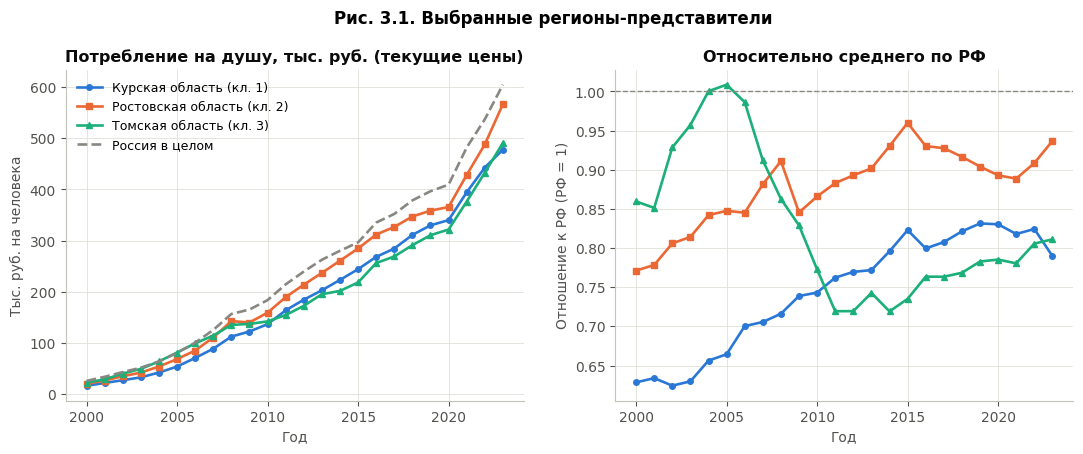

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for r in REGIONS:
    axes[0].plot(W.index, W[r], color=REGION_COLOR[r], marker=CLUSTER_MARKERS[REGION_CLUSTER[r]], markersize=4,
                 label=f'{r} (кл. {REGION_CLUSTER[r]})')
    axes[1].plot(W.index, ratio_rf[r], color=REGION_COLOR[r], marker=CLUSTER_MARKERS[REGION_CLUSTER[r]], markersize=4, label=r)
axes[0].plot(rf.index, rf, color=MUTED, linestyle='--', label='Россия в целом')
axes[1].axhline(1, color=MUTED, linestyle='--', linewidth=1)
thousands(axes[0])
axes[0].set_title('Потребление на душу, тыс. руб. (текущие цены)')
axes[0].set_ylabel('Тыс. руб. на человека')
axes[1].set_title('Относительно среднего по РФ')
axes[1].set_ylabel('Отношение к РФ (РФ = 1)')
for ax in axes:
    ax.set_xlabel('Год')
axes[0].legend(loc='upper left')
fig.suptitle('Рис. 3.1. Выбранные регионы-представители', fontweight='bold', y=1.02)
save_fig(fig, '09_selected_series')
plt.show()

**Комментарий.** У всех трёх регионов наклон линейного тренда положителен и статистически значим (p < 0,001):
19,6 тыс. руб. в год у Курской, 21,7 тыс. у Ростовской и 17,8 тыс. у Томской области.
* R² линейного тренда (0,95–0,97) даже немного выше, чем у лог-линейного (0,94). Причина в том, что рост не строго
  экспоненциальный: темпы прироста снижались с 25–35% в начале 2000-х до 5–10% в конце 2010-х, поэтому в логарифмах тренд вогнутый.
  Ни прямая, ни экспонента с постоянным темпом не описывают ряд полностью, нужны модели с **адаптивным** трендом
  (Holt, ARIMA с d = 2).
* Логарифм на этапах 4–5 всё равно используем. Он стабилизирует разброс (колебания в рублях растут вместе с уровнем) и делает
  тренд «процентным». На этапе 5 это подтвердится: модели на логарифмах точнее моделей на рублях.
* Относительно России в целом (рис. 3.1, справа) Курская область подтянулась с 0,63 до 0,79 среднероссийского уровня,
  Ростовская с 0,77 до 0,94, а Томская опустилась с 0,86 до 0,81. Последнее типично для кластера 3: «сближение сверху».

---
# Этап 4. Анализ выбранных регионов
## 4.1. Тренд: скользящее среднее и фильтр Ходрика — Прескотта
* **Скользящее среднее** берём центрированное, окно 3 года. Это минимальное окно, которое сглаживает годовые колебания, не съедая
  короткий ряд (теряется по одной точке с каждого края).
* **HP-фильтр** применяем к **логарифму** ряда. Тогда циклическая компонента измеряется в процентах отклонения от тренда и
  сопоставима между годами с разным уровнем цен. Параметр сглаживания λ = 6,25 рекомендован Равном и Улигом (2002) для годовых
  данных; λ = 1600 подходит для квартальных и здесь дал бы слишком жёсткий тренд.

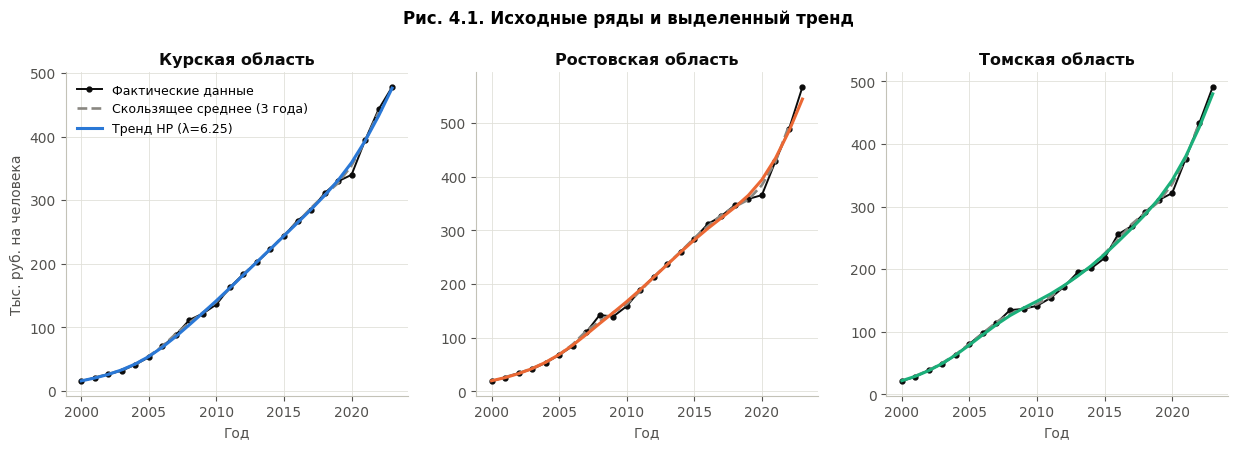

In [26]:
HP_LAMBDA = 6.25
trend_info = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=False)
for ax, r in zip(axes, REGIONS):
    s = W[r]
    ma3 = s.rolling(3, center=True).mean()
    cyc, tr = hpfilter(np.log(s), lamb=HP_LAMBDA)
    trend_info[r] = {'cycle_pct': cyc * 100, 'hp_trend': np.exp(tr)}
    ax.plot(s.index, s, color=INK, marker='o', markersize=3.5, linewidth=1.4, label='Фактические данные')
    ax.plot(ma3.index, ma3, color=MUTED, linestyle='--', label='Скользящее среднее (3 года)')
    ax.plot(s.index, np.exp(tr), color=REGION_COLOR[r], linewidth=2.2, label=f'Тренд HP (λ={HP_LAMBDA})')
    thousands(ax)
    ax.set_title(r)
    ax.set_xlabel('Год')
axes[0].set_ylabel('Тыс. руб. на человека')
axes[0].legend(loc='upper left')
fig.suptitle('Рис. 4.1. Исходные ряды и выделенный тренд', fontweight='bold', y=1.03)
save_fig(fig, '10_trend_ma_hp')
plt.show()

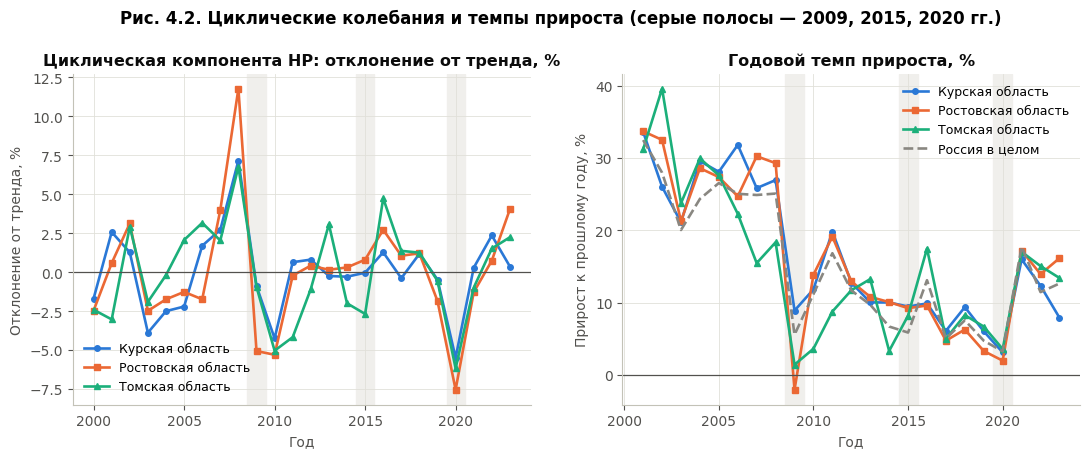

Циклическая компонента (% от тренда) в ключевые годы:


,Курская область,Ростовская область,Томская область
year,,,
2008,7.16,11.78,6.77
2009,-0.89,-5.06,-0.95
2010,-4.25,-5.30,-5.04
2014,-0.29,0.31,-2.00
2015,-0.03,0.80,-2.68
2016,1.28,2.72,4.74
2019,-0.47,-1.85,-0.55
2020,-5.49,-7.54,-6.17
2021,0.28,-1.29,-1.00


Ст. отклонение циклической компоненты, п.п.: {'Курская область': 2.62, 'Ростовская область': 3.78, 'Томская область': 3.16}


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for r in REGIONS:
    c = REGION_COLOR[r]; mk = CLUSTER_MARKERS[REGION_CLUSTER[r]]
    axes[0].plot(W.index, trend_info[r]['cycle_pct'], color=c, marker=mk, markersize=4, label=r)
    axes[1].plot(W.index[1:], (W[r].pct_change() * 100).iloc[1:], color=c, marker=mk, markersize=4, label=r)
axes[1].plot(rf.index[1:], (rf.pct_change() * 100).iloc[1:], color=MUTED, linestyle='--', label='Россия в целом')
for ax in axes:
    for y in (2009, 2015, 2020):
        ax.axvspan(y - 0.5, y + 0.5, color=BAND, zorder=0)
    ax.axhline(0, color=INK2, linewidth=0.9)
    ax.set_xlabel('Год')
axes[0].set_title('Циклическая компонента HP: отклонение от тренда, %')
axes[0].set_ylabel('Отклонение от тренда, %')
axes[1].set_title('Годовой темп прироста, %')
axes[1].set_ylabel('Прирост к прошлому году, %')
axes[0].legend(loc='lower left')
axes[1].legend(loc='upper right')
fig.suptitle('Рис. 4.2. Циклические колебания и темпы прироста (серые полосы — 2009, 2015, 2020 гг.)', fontweight='bold', y=1.03)
save_fig(fig, '11_cycles_growth')
plt.show()

cyc_tab = pd.DataFrame({r: trend_info[r]['cycle_pct'] for r in REGIONS})
print('Циклическая компонента (% от тренда) в ключевые годы:')
display(cyc_tab.loc[[2008, 2009, 2010, 2014, 2015, 2016, 2019, 2020, 2021, 2022, 2023]].round(2))
print('Ст. отклонение циклической компоненты, п.п.:', cyc_tab.std().round(2).to_dict())

**Почему нет сезонной декомпозиции.** Сезонность — это повторяющийся паттерн внутри года (по месяцам или кварталам).
У годового ряда одно наблюдение в год, поэтому периода внутри года просто нет (частота = 1). Формально `seasonal_decompose`
с периодом 1 вернул бы нулевую сезонную компоненту, а любой период больше 1 (например, 2 или 4 года) был бы произвольным и
не соответствовал бы никакому сезонному механизму. Колебания вокруг тренда в этих данных связаны с **деловым циклом и шоками**
(2009, 2015, 2020 гг.). Они нерегулярны по длительности и амплитуде, поэтому их корректнее анализировать как циклическую
компоненту HP-фильтра, а не как сезонность.

## 4.2. Тест Дики — Фуллера на стационарность
Проверяем четыре представления ряда: уровень, логарифм, первую разность логарифма (≈ темп прироста) и вторую разность логарифма
(≈ изменение темпа). Для рядов с трендом используем ADF с константой и трендом (`ct`), для разностей только с константой (`c`).
Число лагов выбираем по AIC при `maxlag = 3`: правило Швёрта для n = 24 дало бы 8 лагов, а это слишком много степеней свободы
для такого короткого ряда. **H₀ ADF: единичный корень (ряд нестационарен).** В качестве проверки добавлен тест KPSS
с противоположной гипотезой (**H₀ KPSS: ряд стационарен**). Если оба теста согласны, вывод надёжнее.

In [28]:
def adf_kpss(x, regression):
    a = adfuller(x, regression=regression, maxlag=3, autolag='AIC')
    k = kpss(x, regression=regression, nlags='auto')
    adf_st = a[1] < 0.05      # отвергаем единичный корень
    kpss_st = k[1] >= 0.05    # не отвергаем стационарность
    verdict = ('стационарен' if adf_st and kpss_st else 'нестационарен' if (not adf_st and not kpss_st)
               else 'противоречиво')
    return {'ADF stat': a[0], 'ADF p': a[1], 'лаги': a[2], 'KPSS stat': k[0], 'KPSS p': k[1], 'вывод': verdict}

TRANSFORMS = [('уровень', lambda s: s, 'ct'), ('ln', lambda s: np.log(s), 'ct'),
              ('Δln', lambda s: np.log(s).diff().dropna(), 'c'), ('Δ²ln', lambda s: np.log(s).diff().diff().dropna(), 'c')]
adf_rows = []
for r in REGIONS:
    for name, fn, reg in TRANSFORMS:
        adf_rows.append({'регион': r, 'ряд': name, 'спецификация': reg, **adf_kpss(fn(W[r]).values, reg)})
adf_tab = pd.DataFrame(adf_rows)
save_tab(adf_tab, 'adf_kpss', index=False)
display(adf_tab.round(3))
RESULTS['adf'] = adf_tab.to_dict(orient='records')

,регион,ряд,спецификация,ADF stat,ADF p,лаги,KPSS stat,KPSS p,вывод
0,Курская область,уровень,ct,-0.023,0.994,0,0.187,0.021,нестационарен
1,Курская область,ln,ct,-2.243,0.466,0,0.186,0.021,нестационарен
2,Курская область,Δln,c,-2.116,0.238,0,0.586,0.024,нестационарен
3,Курская область,Δ²ln,c,-5.899,0.000,0,0.137,0.100,стационарен
4,Ростовская область,уровень,ct,1.151,1.000,0,0.178,0.024,нестационарен
5,Ростовская область,ln,ct,-2.665,0.251,0,0.183,0.022,нестационарен
6,Ростовская область,Δln,c,-2.656,0.082,0,0.517,0.038,нестационарен
7,Ростовская область,Δ²ln,c,-5.421,0.000,1,0.293,0.100,стационарен
8,Томская область,уровень,ct,2.483,1.000,0,0.177,0.025,нестационарен
9,Томская область,ln,ct,-3.807,0.016,1,0.162,0.037,противоречиво


**Интерпретация ADF/KPSS:**
* **Уровень нестационарен** во всех трёх регионах: ADF p = 0,99–1,00, KPSS p ≈ 0,02 < 0,05, оба теста согласны.
  Ряд с выраженным трендом и растущим средним моделировать в уровнях нельзя.
* **Логарифм нестационарен** у Курской (ADF p = 0,47) и Ростовской (p = 0,25) областей, KPSS также отвергает стационарность
  (p = 0,02). Особый случай — **Томская область**: ADF с трендом отвергает единичный корень (p = 0,016), а KPSS отвергает
  стационарность (p = 0,037). Противоречие возникает потому, что лог-тренд Томской области не линейный, а вогнутый
  (темп роста снижается). ADF принимает это за возврат к линейному тренду. Решаем в пользу нестационарности.
* **Первая разность логарифма (темп прироста) тоже нестационарна**: ADF p = 0,24 (Курская), 0,08 (Ростовская), 0,16 (Томская);
  KPSS отвергает стационарность у Курской (p = 0,024) и Ростовской (p = 0,038), у Томской находится на грани (p = 0,067).
  Причина видна на рис. 4.2: темп прироста снижался с 25–35% в начале 2000-х до 3–10% в 2017–2020 гг., в основном из-за
  замедления инфляции. Значит, у темпа роста есть собственный тренд.
* **Вторая разность логарифма стационарна** во всех регионах: ADF p < 0,001, KPSS p ≥ 0,1, оба теста согласны.
  **Вывод: ln(ряда) интегрирован порядка 2, для ARIMA на логарифмах d = 2.** Тот же вывод даёт автоматическая процедура выбора d
  на обучающей выборке (этап 5). Ростовская область ближе всех к I(1) (ADF для Δln p = 0,08).
* Оговорка: на 22–24 наблюдениях мощность тестов невелика, поэтому вывод делаем по согласию двух тестов и графиков ACF.

## 4.3. ACF и PACF
Строим автокорреляции для логарифма, первой и второй разности логарифма (до 10 лагов, это меньше n/2 для PACF).
Доверительные границы 95%: для ACF по формуле Бартлетта, для PACF ±1,96/√n.

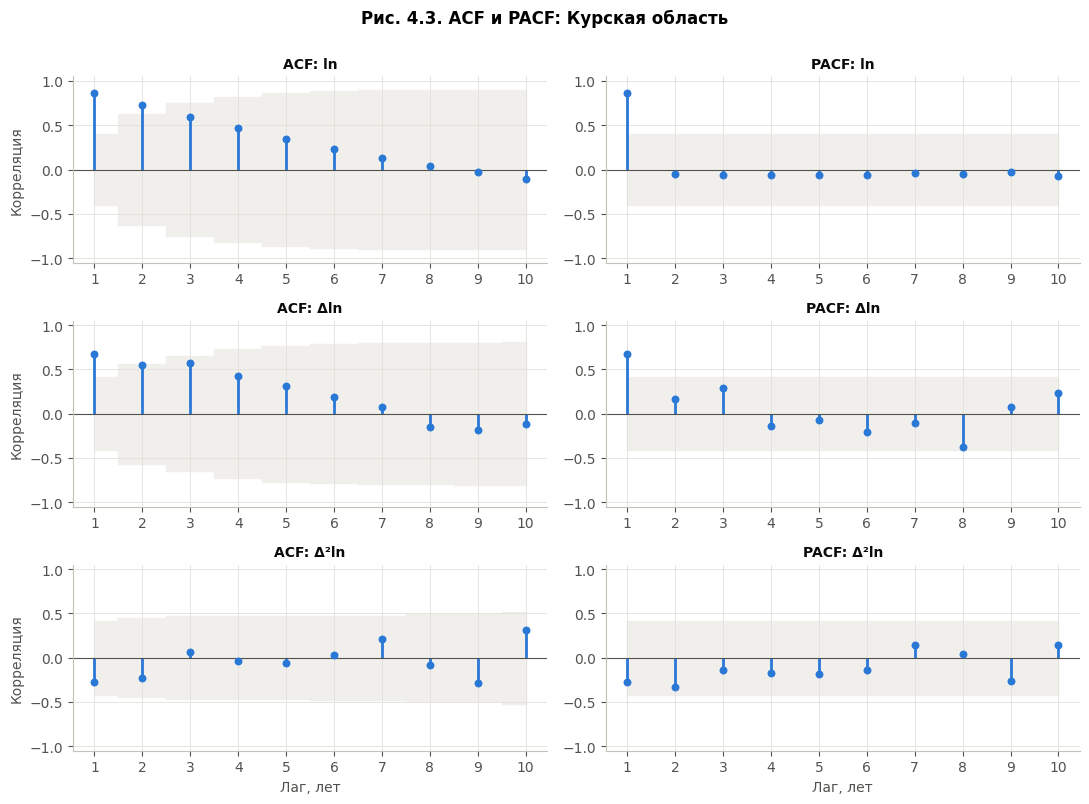

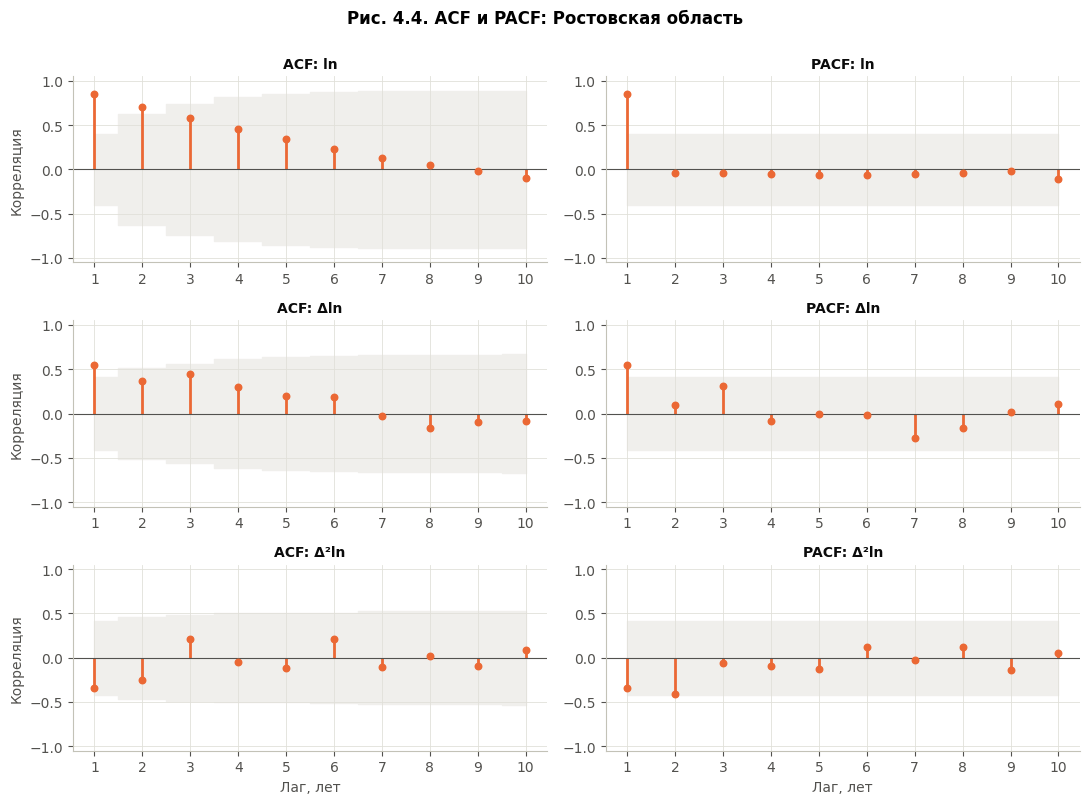

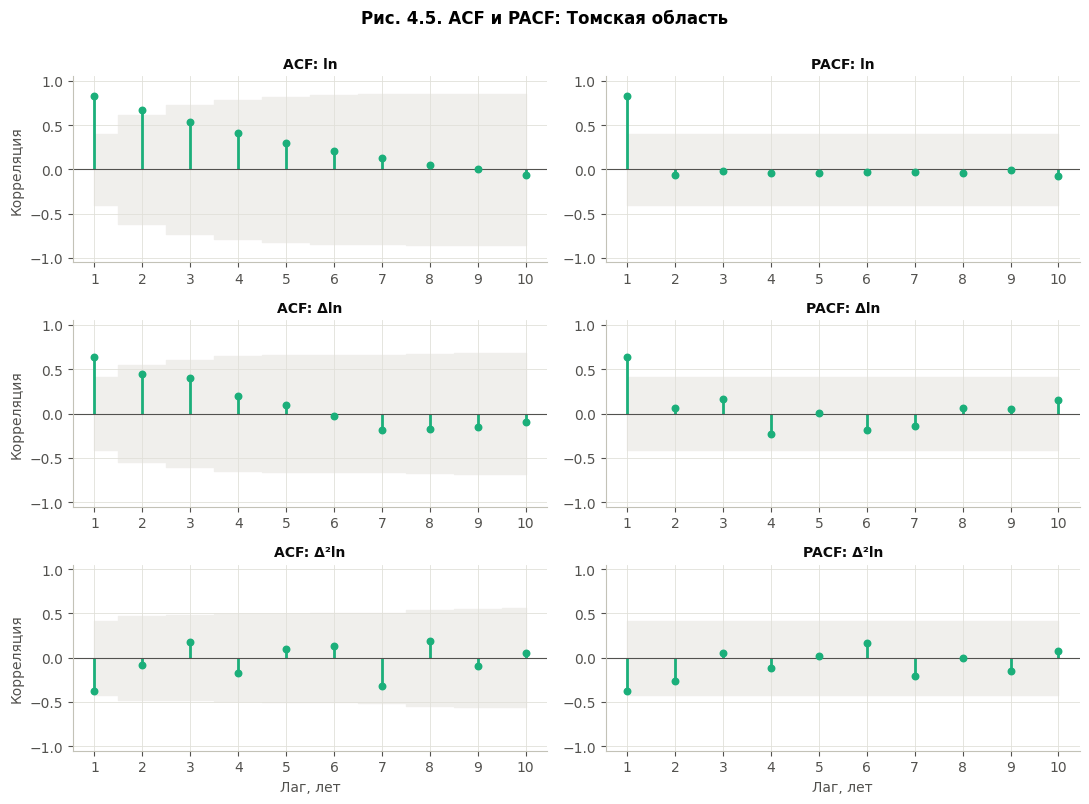

,регион,ряд,n,граница ±1.96/√n,ACF1,ACF2,ACF3,PACF1,PACF2,PACF3
0,Курская область,ln,24,0.40,0.86,0.72,0.59,0.86,-0.05,-0.06
1,Курская область,Δln,23,0.41,0.67,0.55,0.57,0.67,0.17,0.29
2,Курская область,Δ²ln,22,0.42,-0.28,-0.23,0.06,-0.28,-0.33,-0.14
3,Ростовская область,ln,24,0.40,0.85,0.71,0.58,0.85,-0.04,-0.04
4,Ростовская область,Δln,23,0.41,0.55,0.36,0.44,0.55,0.09,0.31
5,Ростовская область,Δ²ln,22,0.42,-0.34,-0.25,0.21,-0.34,-0.41,-0.06
6,Томская область,ln,24,0.40,0.83,0.67,0.54,0.83,-0.06,-0.02
7,Томская область,Δln,23,0.41,0.64,0.45,0.40,0.64,0.07,0.16
8,Томская область,Δ²ln,22,0.42,-0.38,-0.08,0.18,-0.38,-0.26,0.05


In [29]:
def corr_panel(ax, x, kind, color, title):
    n_l = 10
    if kind == 'ACF':
        vals, ci = acf(x, nlags=n_l, alpha=0.05)
    else:
        vals, ci = pacf(x, nlags=n_l, alpha=0.05, method='ywm')
    lags = np.arange(len(vals))
    half = ci[:, 1] - vals
    ax.fill_between(lags[1:], -half[1:], half[1:], color=BAND, step='mid', zorder=0, label='95% граница')
    ax.vlines(lags[1:], 0, vals[1:], color=color, linewidth=2)
    ax.scatter(lags[1:], vals[1:], color=color, s=22, zorder=3)
    ax.axhline(0, color=INK2, linewidth=0.8)
    ax.set_ylim(-1.05, 1.05)
    ax.set_xticks(range(1, n_l + 1))
    ax.set_title(title, fontsize=10)
    return vals

acf_rows = []
for i, r in enumerate(REGIONS, start=1):
    ls = np.log(W[r])
    variants = [('ln', ls), ('Δln', ls.diff().dropna()), ('Δ²ln', ls.diff().diff().dropna())]
    fig, axes = plt.subplots(3, 2, figsize=(11, 8))
    for row, (nm, x) in enumerate(variants):
        va = corr_panel(axes[row, 0], x.values, 'ACF', REGION_COLOR[r], f'ACF: {nm}')
        vp = corr_panel(axes[row, 1], x.values, 'PACF', REGION_COLOR[r], f'PACF: {nm}')
        acf_rows.append({'регион': r, 'ряд': nm, 'n': len(x), 'граница ±1.96/√n': 1.96 / np.sqrt(len(x)),
                         **{f'ACF{l}': va[l] for l in (1, 2, 3)}, **{f'PACF{l}': vp[l] for l in (1, 2, 3)}})
        axes[row, 0].set_ylabel('Корреляция')
    for ax in axes[-1]:
        ax.set_xlabel('Лаг, лет')
    fig.suptitle(f'Рис. 4.{2 + i}. ACF и PACF: {r}', fontweight='bold', y=1.0)
    fig.tight_layout()
    save_fig(fig, f'12_acf_pacf_{i}')
    plt.show()

acf_tab = pd.DataFrame(acf_rows)
save_tab(acf_tab, 'acf_pacf_values', index=False)
display(acf_tab.round(2))

**Гипотезы о порядках p и q (по графикам):**
* **ln(ряда)**: ACF убывает медленно и почти линейно (0,83–0,86 на лаге 1 и 0,54–0,59 на лаге 3), у PACF один большой пик
  на лаге 1 (0,83–0,86), остальные около нуля.
  Это классическая картина единичного корня, нужно дифференцирование.
* **Δln**: ACF всё ещё убывает медленно (у Курской 0,67; 0,55; 0,57 на лагах 1–3), PACF значим на лаге 1.
  Это признак оставшейся нестационарности (тренд темпов роста), что согласуется с ADF. Модель AR(1) для Δln, то есть ARIMA(1,1,0),
  формально возможна, но не учитывает снижение темпов.
* **Δ²ln**: все автокорреляции внутри границ (|r| < 0,42). ACF на лаге 1 **отрицательна** (−0,28 у Курской, −0,34 у Ростовской,
  −0,38 у Томской) и дальше быстро затухает, а PACF отрицательна на лагах 1–2 и постепенно затухает. Такой паттерн
  («обрыв» ACF после лага 1 и затухающая PACF) характерен для **MA(1)**.

**Основная гипотеза для всех трёх регионов: ARIMA(0,2,1) на ln(ряда).** Альтернативы: ARIMA(1,2,0)/(2,2,0), так как PACF
отрицательна на лагах 1–2 (у Ростовской PACF₂ = −0,41, почти на границе), и ARIMA(0,2,0), так как формально ни одна
автокорреляция не значима. На этапе 5 сравним гипотезу с автоматическим подбором по AICc.

## 4.4. Сравнение регионов

In [30]:
cmp_rows = {}
for r in REGIONS:
    s = W[r]; g = s.pct_change().dropna()
    a = adf_tab[adf_tab['регион'] == r].set_index('ряд')
    a2 = acf_tab[(acf_tab['регион'] == r) & (acf_tab['ряд'] == 'Δ²ln')].iloc[0]
    cmp_rows[r] = {
        'кластер': REGION_CLUSTER[r],
        'наклон тренда, тыс. руб./год': base.loc['наклон тренда, руб./год', r] / 1000,
        'R² линейного тренда': base.loc['R² линейного тренда', r],
        'CAGR 2000–2023, %': feats.loc[r, 'cagr'] * 100,
        'CAGR 2000–2011, %': ((s[2011] / s[2000]) ** (1 / 11) - 1) * 100,
        'CAGR 2011–2023, %': ((s[2023] / s[2011]) ** (1 / 12) - 1) * 100,
        'CV ряда': feats.loc[r, 'cv'],
        'волатильность темпа (σ Δln), п.п.': np.log(s).diff().std() * 100,
        'σ цикла HP, п.п.': trend_info[r]['cycle_pct'].std(),
        'мин. годовой прирост, %': g.min() * 100,
        'год мин. прироста': int(g.idxmin()),
        'ADF p: ln': a.loc['ln', 'ADF p'], 'ADF p: Δln': a.loc['Δln', 'ADF p'], 'ADF p: Δ²ln': a.loc['Δ²ln', 'ADF p'],
        'ACF1 Δ²ln': a2['ACF1'], 'PACF2 Δ²ln': a2['PACF2'],
    }
cmp_tab = pd.DataFrame(cmp_rows)
save_tab(cmp_tab, 'region_comparison')
display(cmp_tab.round(3))
RESULTS['comparison'] = cmp_tab.to_dict()

,Курская область,Ростовская область,Томская область
кластер,1.000,2.000,3.000
"наклон тренда, тыс. руб./год",19.576,21.679,17.833
R² линейного тренда,0.968,0.963,0.945
"CAGR 2000–2023, %",16.015,15.843,14.579
"CAGR 2000–2011, %",23.727,23.079,19.623
"CAGR 2011–2023, %",9.369,9.585,10.143
CV ряда,0.737,0.714,0.678
"волатильность темпа (σ Δln), п.п.",7.993,9.048,8.680
"σ цикла HP, п.п.",2.622,3.777,3.159
"мин. годовой прирост, %",3.114,-2.038,1.417


**Выводы по сравнению регионов** (числа из таблицы выше и рис. 4.1–4.5):
* **Тренд.** В абсолютных величинах тренд сильнее всего выражен у Ростовской области: наклон 21,7 тыс. руб./год против
  19,6 у Курской и 17,8 у Томской. В относительных темпах быстрее всех росла Курская область (CAGR 16,0%), затем Ростовская
  (15,8%), медленнее всех Томская (14,6%). Замедление роста видно у всех трёх, но разное по силе:
  * Курская: 23,7% в год (2000–2011) → 9,4% (2011–2023), то есть в 2,5 раза;
  * Ростовская: 23,1% → 9,6%;
  * Томская: 19,6% → 10,1%, только в 2 раза. Во второй половине периода Томская область росла быстрее двух других.
* **Волатильность выше всего у Ростовской области**: σ годовых темпов 9,0 п.п., σ циклической компоненты HP 3,8 п.п.
  У неё самый сильный «перегрев» в 2008 г. (+11,8% выше тренда), единственный среди трёх номинальный спад (−2,0% в 2009 г.)
  и самый глубокий провал 2020 г. (−7,5% от тренда). На втором месте Томская область (σ цикла 3,2 п.п., σ темпов 8,7 п.п.)
  с «пилообразной» динамикой 2013–2017 гг. (прирост 13,3% → 3,3% → 8,2% → 17,5% → 5,0%), в которой отражается ресурсный характер
  экономики. Курская область самая гладкая: σ цикла 2,6 п.п., σ темпов 8,0 п.п., наименьший прирост +3,1% в 2020 г.
* **Стационарность**: ни один ряд не стационарен в уровнях и логарифмах. Все становятся стационарными после второй разности
  логарифма (I(2)). Ростовская ближе всех к I(1) (ADF для Δln p = 0,08). У Томской противоречивые результаты ADF и KPSS
  для ln и Δln из-за вогнутого тренда.
* **ACF/PACF** похожи по форме: медленно затухающая ACF у ln и Δln, отрицательная ACF₁ у Δ²ln. Отрицательная автокорреляция
  на первом лаге сильнее всего у Томской области (−0,38): ускорение темпа роста там чаще всего сменяется замедлением в следующем
  году, что согласуется с «пилой» 2013–2017 гг. У Ростовской заметнее отрицательная PACF на лаге 2 (−0,41).
  У Курской все корреляции Δ²ln слабее (|r| ≤ 0,33), то есть её ряд ближе всего к «чистому» случайному блужданию темпа роста.

---
# Этап 5. Прогнозирование
## 5.1. Разбиение на train/test и горизонт прогноза
* **Train: 2000–2018 (19 лет, 79%)**, **test: 2019–2023 (5 лет, 21%)**. Это больше требуемых 70%, а в тест попадают три
  разных режима: спокойный 2019 г., пандемийный 2020 г. и всплеск номинального роста 2021–2023 гг. Получается строгая проверка.
* **Горизонт будущего прогноза: 3 года (2024–2026)**, одинаковый для всех регионов. Три года — это горизонт регионального
  бюджетного планирования (очередной год и плановый период). На длинном горизонте ошибка экстраполяции для ряда из 24 точек
  быстро растёт (см. п. 5.6).

In [31]:
TRAIN_END, TEST_START, LAST_YEAR = 2018, 2019, 2023
H_TEST, H_FUTURE = LAST_YEAR - TRAIN_END, 3
TEST_YEARS = list(range(TEST_START, LAST_YEAR + 1))
FUTURE_YEARS = list(range(LAST_YEAR + 1, LAST_YEAR + 1 + H_FUTURE))
n_train = len(W.loc[:TRAIN_END])
print(f'Train: 2000–{TRAIN_END} ({n_train} наблюдений, {n_train/len(W):.0%}); '
      f'test: {TEST_START}–{LAST_YEAR} ({H_TEST} наблюдений); горизонт будущего: {FUTURE_YEARS}')
RESULTS['split'] = {'train_end': TRAIN_END, 'n_train': n_train, 'share_train': n_train / len(W), 'h_test': H_TEST,
                    'h_future': H_FUTURE}

Train: 2000–2018 (19 наблюдений, 79%); test: 2019–2023 (5 наблюдений); горизонт будущего: [2024, 2025, 2026]


## 5.2. Модели
| Модель | Реализация | Зачем |
|---|---|---|
| **Наивный прогноз** | `sktime.NaiveForecaster(strategy="last")` | бейзлайн: прогноз = последнее значение |
| **Holt (уровни)** | `statsmodels Holt` на рублях, аддитивный тренд | классический Holt: линейная экстраполяция |
| **Holt (лог)** | `Holt` на ln(ряда), обратное `exp` | тот же метод, но тренд в процентах, то есть экспоненциальный рост |
| **ARIMA (гипотеза)** | `ARIMA(0,2,1)` на ln(ряда) | порядок из анализа ACF/PACF (этап 4) |
| **ARIMA (авто)** | перебор p, q ∈ {0,1,2} по AICc, d по ADF+KPSS на train | автоматический подбор для сравнения с гипотезой |

Почему логарифм: номинальный ряд растёт экспоненциально, и разброс колебаний растёт вместе с уровнем. В логарифмах рост
становится примерно линейным, а дисперсия стабилизируется. Параметры Holt (α, β, начальные уровень и тренд) оцениваются
минимизацией суммы квадратов ошибок, параметры ARIMA методом максимального правдоподобия. **Все модели и параметры
подбираются только по train**; тест используется исключительно для оценки.

In [32]:
def fc_naive(y, h):
    # Бейзлайн из sktime: последнее наблюдение переносится на весь горизонт.
    yp = y.copy(); yp.index = pd.PeriodIndex(yp.index, freq='Y')
    with warnings.catch_warnings():          # sktime переопределяет фильтры, поэтому глушим его FutureWarning локально
        warnings.simplefilter('ignore')
        f = NaiveForecaster(strategy='last').fit(yp)
        return f.predict(fh=ForecastingHorizon(np.arange(1, h + 1), is_relative=True)).values.astype(float)

def fc_holt_level(y, h):
    return Holt(y.values.astype(float), initialization_method='estimated').fit().forecast(h)

def fit_holt_log(y):
    return Holt(np.log(y.values.astype(float)), initialization_method='estimated').fit()

def fc_holt_log(y, h):
    return np.exp(fit_holt_log(y).forecast(h))

def fit_arima_log(y, order):
    # Для d=1 добавляем дрейф (trend='t' означает константу в разностях); для d=2 константа в уровнях не нужна.
    trend = 't' if order[1] == 1 else 'n'
    return ARIMA(np.log(y.values.astype(float)), order=order, trend=trend).fit()

def make_arima_fc(order):
    return lambda y, h: np.exp(fit_arima_log(y, order).forecast(h))

def choose_d(logy, alpha=0.05, max_d=2):
    # Как в auto_arima: дифференцируем, пока ADF и KPSS не согласятся на стационарности.
    x = np.asarray(logy, dtype=float)
    for d in range(max_d + 1):
        reg = 'ct' if d == 0 else 'c'
        adf_p = adfuller(x, regression=reg, maxlag=3, autolag='AIC')[1]
        kpss_p = kpss(x, regression=reg, nlags='auto')[1]
        if adf_p < alpha and kpss_p >= alpha:
            return d
        x = np.diff(x)
    return max_d

def auto_arima(y, d=None, max_pq=2):
    ly = np.log(y.values.astype(float))
    d = choose_d(ly) if d is None else d
    grid = []
    for p, q in itertools.product(range(max_pq + 1), repeat=2):
        try:
            res = fit_arima_log(y, (p, d, q))
            grid.append({'order': (p, d, q), 'AICc': res.aicc, 'AIC': res.aic})
        except Exception as e:     # редкие неудачи оптимизации на коротком ряду просто пропускаем
            print('не оценилась', (p, d, q), e)
    g = pd.DataFrame(grid).sort_values('AICc').reset_index(drop=True)
    return g.loc[0, 'order'], g

def rmse(a, f):
    return float(np.sqrt(mean_squared_error(a, f)))

def mape(a, f):
    return float(mean_absolute_percentage_error(a, f) * 100)

HYP_ORDER = {r: (0, 2, 1) for r in REGIONS}     # гипотеза из анализа ACF/PACF (п. 4.3)

In [33]:
AUTO_ORDER, auto_grids = {}, {}
for r in REGIONS:
    train = W[r].loc[:TRAIN_END]
    d_sel = choose_d(np.log(train.values))
    AUTO_ORDER[r], auto_grids[r] = auto_arima(train)
    print(f'{r}: d по ADF+KPSS на train = {d_sel}; гипотеза ARIMA{HYP_ORDER[r]}; авто ARIMA{AUTO_ORDER[r]}')
    display(auto_grids[r].head(5).round(2))
    auto_grids[r].assign(order=auto_grids[r]['order'].astype(str)).to_csv(
        TAB_DIR / f'auto_arima_grid_{REGIONS.index(r)+1}.csv', index=False, encoding='utf-8-sig')
RESULTS['auto_order'] = {r: list(o) for r, o in AUTO_ORDER.items()}
RESULTS['hyp_order'] = {r: list(o) for r, o in HYP_ORDER.items()}

Курская область: d по ADF+KPSS на train = 2; гипотеза ARIMA(0, 2, 1); авто ARIMA(0, 2, 0)


,order,AICc,AIC
0,"(0, 2, 0)",-49.20,-49.47
1,"(0, 2, 1)",-48.05,-48.91
2,"(1, 2, 0)",-47.51,-48.36
3,"(2, 2, 0)",-45.37,-47.21
4,"(0, 2, 2)",-45.26,-47.11


Ростовская область: d по ADF+KPSS на train = 2; гипотеза ARIMA(0, 2, 1); авто ARIMA(0, 2, 1)


,order,AICc,AIC
0,"(0, 2, 1)",-35.30,-36.16
1,"(2, 2, 0)",-33.84,-35.68
2,"(0, 2, 0)",-33.55,-33.81
3,"(1, 2, 0)",-32.91,-33.76
4,"(0, 2, 2)",-32.34,-34.19


Томская область: d по ADF+KPSS на train = 2; гипотеза ARIMA(0, 2, 1); авто ARIMA(0, 2, 1)


,order,AICc,AIC
0,"(0, 2, 1)",-39.76,-40.61
1,"(0, 2, 0)",-39.53,-39.80
2,"(1, 2, 0)",-39.40,-40.26
3,"(2, 2, 0)",-37.21,-39.06
4,"(0, 2, 2)",-36.91,-38.76


In [34]:
# Параметры моделей на train: смотрим, что модели «выучили».
param_rows = []
for r in REGIONS:
    train = W[r].loc[:TRAIN_END]
    hl = fit_holt_log(train)
    hv = Holt(train.values.astype(float), initialization_method='estimated').fit()
    ah = fit_arima_log(train, HYP_ORDER[r])
    param_rows.append({'регион': r,
                       'Holt(лог) α': hl.params['smoothing_level'], 'Holt(лог) β': hl.params['smoothing_trend'],
                       'Holt(лог): тренд на конец train, %/год': (np.exp(hl.trend[-1]) - 1) * 100,
                       'Holt(уровни) α': hv.params['smoothing_level'], 'Holt(уровни) β': hv.params['smoothing_trend'],
                       'Holt(уровни): тренд на конец train, тыс. руб./год': hv.trend[-1] / 1000,
                       f'ARIMA{HYP_ORDER[r]} θ1': ah.params[0], 'θ1 p-value': ah.pvalues[0]})
params_tab = pd.DataFrame(param_rows).set_index('регион')
save_tab(params_tab, 'model_params')
display(params_tab.round(3))

,Holt(лог) α,Holt(лог) β,"Holt(лог): тренд на конец train, %/год",Holt(уровни) α,Holt(уровни) β,"Holt(уровни): тренд на конец train, тыс. руб./год","ARIMA(0, 2, 1) θ1",θ1 p-value
регион,,,,,,,,
Курская область,1.000,0.624,8.673,1.000,0.477,22.873,-0.351,0.268
Ростовская область,1.000,0.420,7.219,1.000,0.000,18.519,-0.555,0.422
Томская область,0.868,0.736,7.891,0.998,0.000,15.450,-0.388,0.205


## 5.3. Прогноз на тестовую выборку и метрики RMSE, MAPE

In [35]:
MODEL_NAMES = ['Наивный (sktime)', 'Holt (уровни)', 'Holt (лог)', 'ARIMA гипотеза', 'ARIMA авто']
MODEL_STYLE = {'Наивный (sktime)': (MUTED, '--'), 'Holt (уровни)': (VIOLET, ':'), 'Holt (лог)': (BLUE, '-'),
               'ARIMA гипотеза': (ORANGE, '-'), 'ARIMA авто': (AQUA, '-.')}

def model_fns(r):
    return {'Наивный (sktime)': fc_naive, 'Holt (уровни)': fc_holt_level, 'Holt (лог)': fc_holt_log,
            'ARIMA гипотеза': make_arima_fc(HYP_ORDER[r]), 'ARIMA авто': make_arima_fc(AUTO_ORDER[r])}

def model_label(name, r):
    if name == 'ARIMA гипотеза':
        return f'ARIMA{HYP_ORDER[r]} — гипотеза'
    if name == 'ARIMA авто':
        return f'ARIMA{AUTO_ORDER[r]} — авто'
    return name

test_fc, metric_rows = {}, []
for r in REGIONS:
    train, test = W[r].loc[:TRAIN_END], W[r].loc[TEST_START:]
    naive_rmse = None
    for name, fn in model_fns(r).items():
        f = fn(train, H_TEST)
        test_fc[(r, name)] = pd.Series(f, index=TEST_YEARS)
        row = {'регион': r, 'модель': name, 'спецификация': model_label(name, r),
               'RMSE, руб.': rmse(test, f), 'MAPE, %': mape(test, f),
               'ошибка 2023, %': (test.iloc[-1] - f[-1]) / test.iloc[-1] * 100}
        metric_rows.append(row)
metrics = pd.DataFrame(metric_rows)
naive_ref = metrics[metrics['модель'] == 'Наивный (sktime)'].set_index('регион')
metrics['RMSE к наивному, %'] = metrics.apply(lambda x: x['RMSE, руб.'] / naive_ref.loc[x['регион'], 'RMSE, руб.'] * 100, axis=1)
metrics['MAPE к наивному, %'] = metrics.apply(lambda x: x['MAPE, %'] / naive_ref.loc[x['регион'], 'MAPE, %'] * 100, axis=1)
save_tab(metrics, 'test_metrics', index=False)
display(metrics.round(2))

# Лучшая модель: минимальный MAPE (безразмерен и сопоставим между регионами); при равенстве до 0,01 п.п. — меньший RMSE.
BEST = {}
for r in REGIONS:
    m = metrics[metrics['регион'] == r].copy()
    m['MAPE_r'] = m['MAPE, %'].round(2)
    BEST[r] = m.sort_values(['MAPE_r', 'RMSE, руб.']).iloc[0]['модель']
print('Лучшая модель на тесте:', {r: model_label(BEST[r], r) for r in REGIONS})
RESULTS['test_metrics'] = metrics.to_dict(orient='records')
RESULTS['best'] = {r: model_label(BEST[r], r) for r in REGIONS}
RESULTS['best_key'] = BEST
RESULTS['test_actual'] = {r: W[r].loc[TEST_START:].tolist() for r in REGIONS}
RESULTS['test_fc'] = {f'{r}|{n}': test_fc[(r, n)].tolist() for (r, n) in test_fc}

,регион,модель,спецификация,"RMSE, руб.","MAPE, %","ошибка 2023, %","RMSE к наивному, %","MAPE к наивному, %"
0,Курская область,Наивный (sktime),Наивный (sktime),103408.39,20.02,34.94,100.00,100.00
1,Курская область,Holt (уровни),Holt (уровни),31396.89,6.01,11.02,30.36,30.04
2,Курская область,Holt (лог),Holt (лог),13882.97,3.04,1.40,13.43,15.19
3,Курская область,ARIMA гипотеза,"ARIMA(0, 2, 1) — гипотеза",13878.96,3.04,1.35,13.42,15.16
4,Курская область,ARIMA авто,"ARIMA(0, 2, 0) — авто",16605.33,3.63,-1.85,16.06,18.11
5,Ростовская область,Наивный (sktime),Наивный (sktime),122815.80,19.00,38.80,100.00,100.00
6,Ростовская область,Holt (уровни),Holt (уровни),66009.38,9.85,22.47,53.75,51.86
7,Ростовская область,Holt (лог),Holt (лог),39595.78,6.48,13.28,32.24,34.12
8,Ростовская область,ARIMA гипотеза,"ARIMA(0, 2, 1) — гипотеза",41104.46,6.70,13.89,33.47,35.28
9,Ростовская область,ARIMA авто,"ARIMA(0, 2, 1) — авто",41104.46,6.70,13.89,33.47,35.28


Лучшая модель на тесте: {'Курская область': 'ARIMA(0, 2, 1) — гипотеза', 'Ростовская область': 'Holt (лог)', 'Томская область': 'ARIMA(0, 2, 1) — гипотеза'}


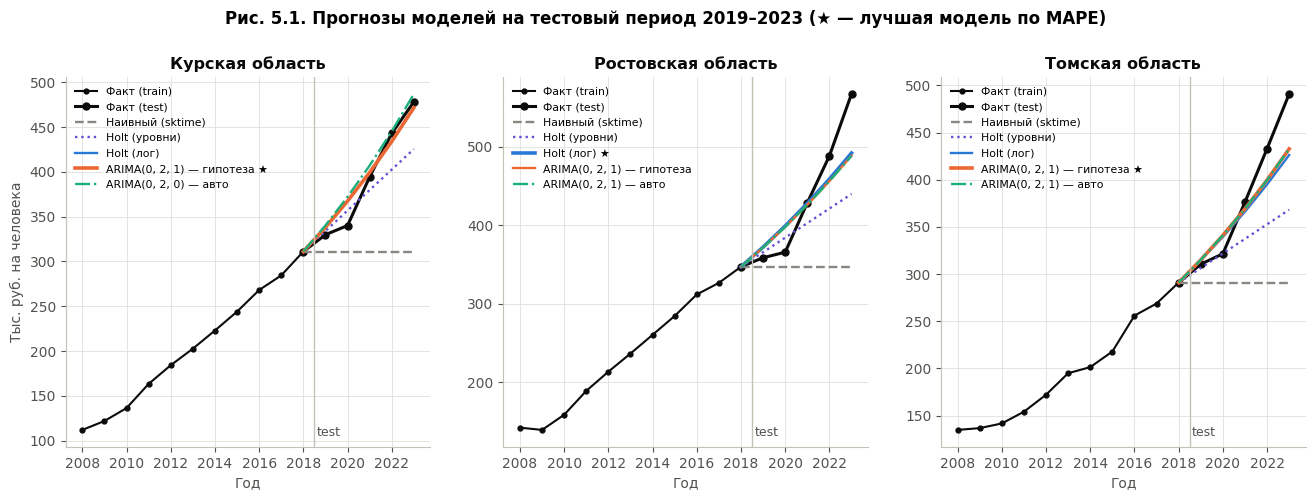

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, r in zip(axes, REGIONS):
    s = W[r].loc[2008:]
    ax.plot(s.loc[:TRAIN_END].index, s.loc[:TRAIN_END], color=INK, marker='o', markersize=3.5, linewidth=1.5, label='Факт (train)')
    ax.plot(s.loc[TRAIN_END:].index, s.loc[TRAIN_END:], color=INK, marker='o', markersize=5, linewidth=2.2, label='Факт (test)')
    for name in MODEL_NAMES:
        col, ls = MODEL_STYLE[name]
        f = test_fc[(r, name)]
        xs = [TRAIN_END] + TEST_YEARS
        ys = [W[r].loc[TRAIN_END]] + f.tolist()
        lw = 2.6 if name == BEST[r] else 1.7
        ax.plot(xs, ys, color=col, linestyle=ls, linewidth=lw, label=model_label(name, r) + (' ★' if name == BEST[r] else ''))
    ax.axvline(TRAIN_END + 0.5, color=AXIS, linewidth=1)
    ax.text(TRAIN_END + 0.6, ax.get_ylim()[0] + 0.03 * np.ptp(ax.get_ylim()), 'test', color=INK2, fontsize=9)
    thousands(ax)
    year_axis(ax)
    ax.set_title(r)
    ax.set_xlabel('Год')
    ax.legend(loc='upper left', fontsize=7.8)
axes[0].set_ylabel('Тыс. руб. на человека')
fig.suptitle('Рис. 5.1. Прогнозы моделей на тестовый период 2019–2023 (★ — лучшая модель по MAPE)', fontweight='bold', y=1.02)
save_fig(fig, '13_test_forecasts')
plt.show()

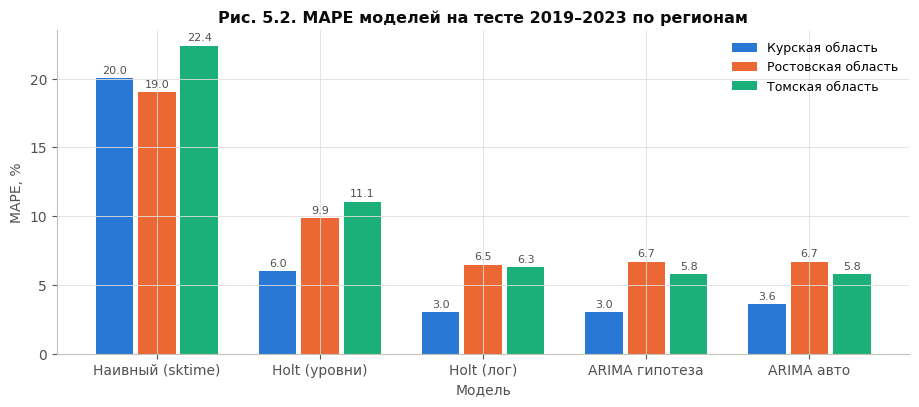

In [37]:
pv = metrics.pivot(index='модель', columns='регион', values='MAPE, %').loc[MODEL_NAMES, REGIONS]
fig, ax = plt.subplots(figsize=(11, 4.2))
w = 0.26
for j, r in enumerate(REGIONS):
    bars = ax.bar(np.arange(len(MODEL_NAMES)) + (j - 1) * w, pv[r], width=w - 0.03, color=REGION_COLOR[r], label=r)
    ax.bar_label(bars, fmt='%.1f', fontsize=8, color=INK2, padding=2)
ax.set_xticks(range(len(MODEL_NAMES)), MODEL_NAMES)
ax.set_title('Рис. 5.2. MAPE моделей на тесте 2019–2023 по регионам')
ax.set_xlabel('Модель')
ax.set_ylabel('MAPE, %')
ax.legend()
save_fig(fig, '14_test_mape')
plt.show()

In [38]:
# Дополнительная проверка выбора d: что было бы при d = 1 (ARIMA на ln с дрейфом, порядок p, q по AICc)?
alt_rows = []
for r in REGIONS:
    train, test = W[r].loc[:TRAIN_END], W[r].loc[TEST_START:]
    o1, g1 = auto_arima(train, d=1)
    f1 = make_arima_fc(o1)(train, H_TEST)
    alt_rows.append({'регион': r, 'лучшая ARIMA с d=1 (с дрейфом)': str(o1), 'MAPE, %': mape(test, f1),
                     'дрейф, % в год': (np.exp(fit_arima_log(train, o1).params[0]) - 1) * 100,
                     'MAPE лучшей модели, %': metrics.set_index(['регион', 'модель']).loc[(r, BEST[r]), 'MAPE, %']})
alt_d = pd.DataFrame(alt_rows)
save_tab(alt_d, 'alt_d1_check', index=False)
display(alt_d.round(2))
RESULTS['alt_d1'] = alt_d.to_dict(orient='records')

,регион,лучшая ARIMA с d=1 (с дрейфом),"MAPE, %","дрейф, % в год","MAPE лучшей модели, %"
0,Курская область,"(1, 1, 0)",14.93,18.85,3.04
1,Ростовская область,"(1, 1, 0)",17.65,17.65,6.48
2,Томская область,"(1, 1, 0)",8.60,16.32,5.79


## 5.4. Стратегия оценки устойчивости: расширяющееся окно (expanding window)
Выбираем **расширяющееся окно**: обучающая выборка всегда начинается в 2000 г. и с каждым шагом увеличивается на год, а модель
**каждый раз заново оценивается**. Скользящее окно фиксированной длины здесь хуже: в ряду всего 24 точки, и при отбрасывании
старых наблюдений окно стало бы слишком коротким для оценки Holt (4 параметра) и ARIMA с d = 2.

Схема: точки прогноза (origin) от 2007 до 2022 г., то есть минимальное обучение 2000–2007 (8 лет). С каждой точки строим прогноз
на 1–3 года вперёд (до 2023 г.). Спецификация лучшей модели (тип и порядок ARIMA) фиксирована, параметры переоцениваются.
Из результатов получаем:
* ошибку **на 1 шаг** за 2019–2023 гг.: её сравниваем с фиксированным разбиением на те же годы;
* ошибку на 1 шаг за **2008–2023 гг.** (16 точек): как меняется качество по мере накопления данных и в кризисные годы
  (эти же ошибки используются в анализе на этапе 6);
* ошибку **по горизонтам 1, 2, 3 года**: насколько надёжен прогноз на 2024–2026 гг.

In [39]:
def expanding_backtest(y, model_fn, first_origin=2007, last_origin=LAST_YEAR - 1, max_h=H_FUTURE):
    rows = []
    for origin in range(first_origin, last_origin + 1):
        train = y.loc[:origin]
        h = min(max_h, LAST_YEAR - origin)
        f = model_fn(train, h)
        for i in range(h):
            t = origin + 1 + i
            rows.append({'origin': origin, 'год': t, 'h': i + 1, 'размер train': len(train),
                         'факт': y.loc[t], 'прогноз': f[i]})
    E = pd.DataFrame(rows)
    E['ошибка, руб.'] = E['факт'] - E['прогноз']           # > 0: модель недооценила, < 0: переоценила
    E['ошибка, %'] = E['ошибка, руб.'] / E['факт'] * 100
    E['APE, %'] = E['ошибка, %'].abs()
    return E

BT = {}
for r in REGIONS:
    BT[r] = expanding_backtest(W[r], model_fns(r)[BEST[r]])
    BT[r].to_csv(TAB_DIR / f'backtest_best_{REGIONS.index(r)+1}.csv', index=False, encoding='utf-8-sig')

stab_rows = []
for r in REGIONS:
    E = BT[r]; e1 = E[E.h == 1]
    fixed = metrics.set_index(['регион', 'модель']).loc[(r, BEST[r])]
    w19 = e1[e1['год'] >= TEST_START]
    stab_rows.append({
        'регион': r, 'лучшая модель': model_label(BEST[r], r),
        'MAPE фикс. split 2019–23 (h=1…5), %': fixed['MAPE, %'],
        'MAPE expanding 2019–23 (h=1), %': w19['APE, %'].mean(),
        'RMSE фикс. split, тыс. руб.': fixed['RMSE, руб.'] / 1000,
        'RMSE expanding 2019–23, тыс. руб.': np.sqrt((w19['ошибка, руб.'] ** 2).mean()) / 1000,
        'MAPE h=1 2008–2013, %': e1[e1['год'].between(2008, 2013)]['APE, %'].mean(),
        'MAPE h=1 2014–2018, %': e1[e1['год'].between(2014, 2018)]['APE, %'].mean(),
        'MAPE h=1 2008–2023, %': e1['APE, %'].mean(),
        'MAPE h=1 без 2009–2010, %': e1[~e1['год'].isin([2009, 2010])]['APE, %'].mean(),
        'MAPE h=2, %': E[E.h == 2]['APE, %'].mean(),
        'MAPE h=3, %': E[E.h == 3]['APE, %'].mean(),
        'MAPE h=3 (цели 2014–2023), %': E[(E.h == 3) & (E['год'] >= 2014)]['APE, %'].mean(),
        'макс. APE h=1, %': e1['APE, %'].max(), 'год макс. APE': int(e1.loc[e1['APE, %'].idxmax(), 'год']),
    })
stability = pd.DataFrame(stab_rows).set_index('регион')
save_tab(stability, 'stability_expanding')
display(stability.round(2).T)
RESULTS['stability'] = stability.to_dict()

регион,Курская область,Ростовская область,Томская область
лучшая модель,"ARIMA(0, 2, 1) — гипотеза",Holt (лог),"ARIMA(0, 2, 1) — гипотеза"
"MAPE фикс. split 2019–23 (h=1…5), %",3.04,6.48,5.79
"MAPE expanding 2019–23 (h=1), %",4.2,5.4,3.7
"RMSE фикс. split, тыс. руб.",13.88,39.6,31.48
"RMSE expanding 2019–23, тыс. руб.",20.58,27.24,18.98
"MAPE h=1 2008–2013, %",5.69,12.26,4.96
"MAPE h=1 2014–2018, %",1.57,2.83,5.69
"MAPE h=1 2008–2023, %",3.94,7.17,4.8
"MAPE h=1 без 2009–2010, %",3.17,3.9,4.13
"MAPE h=2, %",8.46,15.04,10.47


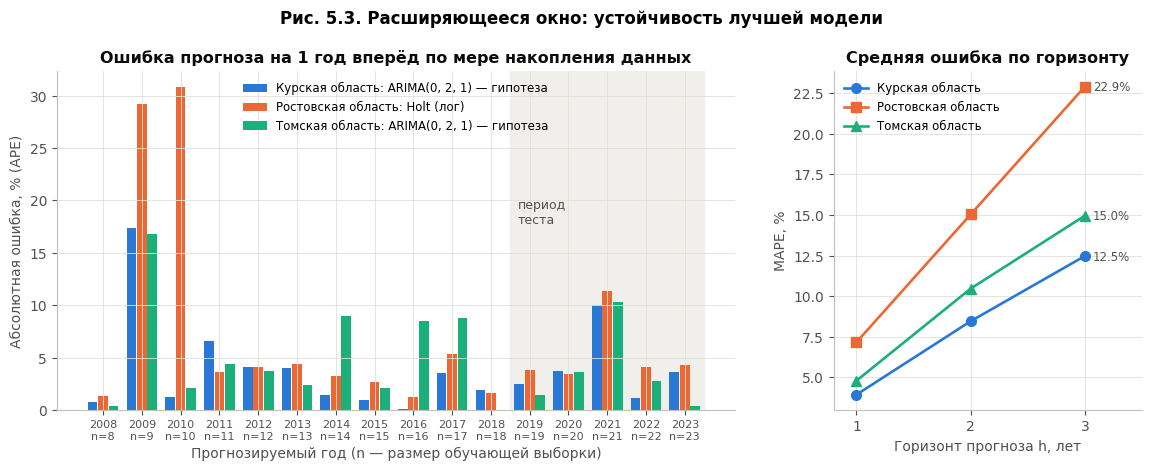

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4), gridspec_kw={'width_ratios': [2.2, 1]})
ax = axes[0]
w = 0.27
for j, r in enumerate(REGIONS):
    e1 = BT[r][BT[r].h == 1]
    ax.bar(e1['год'] + (j - 1) * w, e1['APE, %'], width=w - 0.02, color=REGION_COLOR[r], label=f'{r}: {model_label(BEST[r], r)}')
ax.axvspan(TEST_START - 0.5, LAST_YEAR + 0.5, color=BAND, zorder=0)
ax.text(TEST_START - 0.3, ax.get_ylim()[1] * 0.55, 'период\nтеста', color=INK2, fontsize=9)
e1 = BT[REGIONS[0]][BT[REGIONS[0]].h == 1]
ax.set_xticks(e1['год'], [f"{y}\nn={n}" for y, n in zip(e1['год'], e1['размер train'])], fontsize=8)
ax.set_title('Ошибка прогноза на 1 год вперёд по мере накопления данных')
ax.set_xlabel('Прогнозируемый год (n — размер обучающей выборки)')
ax.set_ylabel('Абсолютная ошибка, % (APE)')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, 1.0), fontsize=8.5)
ax = axes[1]
for r in REGIONS:
    by_h = BT[r].groupby('h')['APE, %'].mean()
    ax.plot(by_h.index, by_h.values, color=REGION_COLOR[r], marker=CLUSTER_MARKERS[REGION_CLUSTER[r]], markersize=7, label=r)
    ax.annotate(f'{by_h.iloc[-1]:.1f}%', (by_h.index[-1], by_h.iloc[-1]), textcoords='offset points', xytext=(6, -3),
                fontsize=8.5, color=INK2)
ax.set_xticks([1, 2, 3])
ax.set_xlim(0.8, 3.5)
ax.set_title('Средняя ошибка по горизонту')
ax.set_xlabel('Горизонт прогноза h, лет')
ax.set_ylabel('MAPE, %')
ax.legend(fontsize=8.5, loc='upper left')
fig.suptitle('Рис. 5.3. Расширяющееся окно: устойчивость лучшей модели', fontweight='bold', y=1.02)
save_fig(fig, '15_expanding_window')
plt.show()

In [41]:
# Для полноты: то же расширяющееся окно (h = 1, 2008–2023) для всех моделей. Устойчив ли рейтинг моделей?
all_bt_rows = []
for r in REGIONS:
    for name, fn in model_fns(r).items():
        E = expanding_backtest(W[r], fn, max_h=1)
        all_bt_rows.append({'регион': r, 'модель': name, 'MAPE h=1 2008–2023, %': E['APE, %'].mean(),
                            'MAPE h=1 2019–2023, %': E[E['год'] >= TEST_START]['APE, %'].mean()})
all_bt = pd.DataFrame(all_bt_rows)
save_tab(all_bt, 'backtest_all_models', index=False)
display(all_bt.pivot(index='модель', columns='регион', values='MAPE h=1 2008–2023, %').loc[MODEL_NAMES, REGIONS].round(2))
display(all_bt.pivot(index='модель', columns='регион', values='MAPE h=1 2019–2023, %').loc[MODEL_NAMES, REGIONS].round(2))
RESULTS['backtest_all'] = all_bt.to_dict(orient='records')

регион,Курская область,Ростовская область,Томская область
модель,,,
Наивный (sktime),9.93,9.81,8.62
Holt (уровни),3.71,5.77,5.70
Holt (лог),5.46,7.17,6.54
ARIMA гипотеза,3.94,5.24,4.80
ARIMA авто,4.21,5.24,4.80


регион,Курская область,Ростовская область,Томская область
модель,,,
Наивный (sktime),8.16,9.19,9.84
Holt (уровни),4.72,6.25,5.24
Holt (лог),4.21,5.40,4.00
ARIMA гипотеза,4.20,5.29,3.70
ARIMA авто,4.89,5.29,3.70


## 5.5. Прогноз на 2024–2026 гг.
Лучшую модель каждого региона переоцениваем на **всех данных 2000–2023** и строим прогноз на 3 года.
Интервалы прогноза (80% и 95%) считаем в логарифмах и переводим обратно через `exp`, поэтому они асимметричны.
* Для ARIMA используем аналитические интервалы statsmodels (`get_forecast`).
* Для Holt используем дисперсию модели ETS(A,A,N), эквивалентной Holt: σ²ₕ = σ²·[1 + (h−1)(α² + αβh + β²h(2h−1)/6)],
  где β = α·β* (β* — параметр сглаживания тренда в Holt), σ² — дисперсия остатков на train.

Для сравнения рядом приводим точечные прогнозы остальных моделей. Их разброс показывает модельную неопределённость.

In [42]:
Z80, Z95 = stats.norm.ppf(0.90), stats.norm.ppf(0.975)

def future_with_pi(y, best_name, r, h=H_FUTURE):
    if best_name == 'Holt (лог)':
        m = fit_holt_log(y)
        mean_log = m.forecast(h)
        a, bstar = m.params['smoothing_level'], m.params['smoothing_trend']
        b = a * bstar
        resid = np.log(y.values) - m.fittedvalues
        sigma2 = np.sum(resid ** 2) / (len(y) - 4)          # 4 оцениваемых параметра: α, β, l0, b0
        hh = np.arange(1, h + 1)
        se = np.sqrt(sigma2 * (1 + (hh - 1) * (a ** 2 + a * b * hh + b ** 2 * hh * (2 * hh - 1) / 6)))
    elif best_name.startswith('ARIMA'):
        order = HYP_ORDER[r] if best_name == 'ARIMA гипотеза' else AUTO_ORDER[r]
        res = fit_arima_log(y, order)
        fc = res.get_forecast(h)
        mean_log, se = fc.predicted_mean, fc.se_mean
    elif best_name == 'Holt (уровни)':
        m = Holt(y.values.astype(float), initialization_method='estimated').fit()
        pt = m.forecast(h)
        return pd.DataFrame({'прогноз': pt}, index=FUTURE_YEARS)
    else:
        pt = fc_naive(y, h)
        return pd.DataFrame({'прогноз': pt}, index=FUTURE_YEARS)
    out = pd.DataFrame({'прогноз': np.exp(mean_log),
                        'нижн. 80%': np.exp(mean_log - Z80 * se), 'верхн. 80%': np.exp(mean_log + Z80 * se),
                        'нижн. 95%': np.exp(mean_log - Z95 * se), 'верхн. 95%': np.exp(mean_log + Z95 * se)},
                       index=FUTURE_YEARS)
    return out

FUT, fut_rows = {}, []
for r in REGIONS:
    y = W[r]
    F = future_with_pi(y, BEST[r], r)
    prev = np.r_[y.iloc[-1], F['прогноз'].values[:-1]]
    F['прирост к пред. году, %'] = (F['прогноз'] / prev - 1) * 100
    for name, fn in model_fns(r).items():
        if name != BEST[r]:
            F[f'для сравнения: {model_label(name, r)}'] = fn(y, H_FUTURE)
    FUT[r] = F
    print(f'\n{r} — лучшая модель: {model_label(BEST[r], r)}')
    display((F / 1).round(1))
    F.to_csv(TAB_DIR / f'future_forecast_{REGIONS.index(r)+1}.csv', encoding='utf-8-sig')
    fut_rows.append({'регион': r, 'модель': model_label(BEST[r], r), 'факт 2023': y.iloc[-1],
                     **{f'прогноз {yr}': F.loc[yr, 'прогноз'] for yr in FUTURE_YEARS},
                     'нижн. 80% 2026': F.loc[FUTURE_YEARS[-1], 'нижн. 80%'], 'верхн. 80% 2026': F.loc[FUTURE_YEARS[-1], 'верхн. 80%'],
                     'нижн. 95% 2026': F.loc[FUTURE_YEARS[-1], 'нижн. 95%'], 'верхн. 95% 2026': F.loc[FUTURE_YEARS[-1], 'верхн. 95%'],
                     'рост 2023→2026, %': (F.loc[FUTURE_YEARS[-1], 'прогноз'] / y.iloc[-1] - 1) * 100,
                     'ср. годовой рост 2024–2026, %': ((F.loc[FUTURE_YEARS[-1], 'прогноз'] / y.iloc[-1]) ** (1 / 3) - 1) * 100,
                     'ср. годовой рост 2018–2023 (факт), %': ((y.loc[2023] / y.loc[2018]) ** (1 / 5) - 1) * 100})
future_summary = pd.DataFrame(fut_rows).set_index('регион')
save_tab(future_summary, 'future_summary')
display(future_summary.round(1).T)
RESULTS['future'] = {r: FUT[r].reset_index().rename(columns={'index': 'год'}).to_dict(orient='records') for r in REGIONS}
RESULTS['future_summary'] = future_summary.to_dict()


Курская область — лучшая модель: ARIMA(0, 2, 1) — гипотеза


,прогноз,нижн. 80%,верхн. 80%,нижн. 95%,верхн. 95%,"прирост к пред. году, %",для сравнения: Наивный (sktime),для сравнения: Holt (уровни),для сравнения: Holt (лог),"для сравнения: ARIMA(0, 2, 0) — авто"
2024,523796.1,490522.2,559327.1,473772.4,579101.6,9.6,478025.8,515362.1,523936.8,515869.9
2025,573948.8,508205.7,648196.7,476508.9,691313.9,9.6,478025.8,552698.4,574257.2,556710.1
2026,628903.6,522741.3,756626.1,474001.9,834426.6,9.6,478025.8,590034.7,629410.5,600783.5



Ростовская область — лучшая модель: Holt (лог)


,прогноз,нижн. 80%,верхн. 80%,нижн. 95%,верхн. 95%,"прирост к пред. году, %",для сравнения: Наивный (sktime),для сравнения: Holt (уровни),"для сравнения: ARIMA(0, 2, 1) — гипотеза","для сравнения: ARIMA(0, 2, 1) — авто"
2024,643186.8,584400.3,707886.8,555487.9,744731.3,13.4,567031.5,641276.2,644544.1,644544.1
2025,729570.1,617042.0,862619.6,564679.4,942610.0,13.4,567031.5,716170.5,732652.6,732652.6
2026,827555.1,647662.4,1057414.4,568850.8,1203914.1,13.4,567031.5,791064.8,832805.4,832805.4



Томская область — лучшая модель: ARIMA(0, 2, 1) — гипотеза


,прогноз,нижн. 80%,верхн. 80%,нижн. 95%,верхн. 95%,"прирост к пред. году, %",для сравнения: Наивный (sktime),для сравнения: Holt (уровни),для сравнения: Holt (лог),"для сравнения: ARIMA(0, 2, 1) — авто"
2024,557649.2,514900.4,603947.1,493613.6,629992.0,13.6,490980.8,545776.2,559864.5,557649.2
2025,633370.2,545013.0,736051.9,503344.3,796984.9,13.6,490980.8,600571.6,638117.4,633370.2
2026,719373.1,571238.4,905922.3,505601.3,1023529.0,13.6,490980.8,655367.0,727307.8,719373.1


регион,Курская область,Ростовская область,Томская область
модель,"ARIMA(0, 2, 1) — гипотеза",Holt (лог),"ARIMA(0, 2, 1) — гипотеза"
факт 2023,478025.8,567031.5,490980.8
прогноз 2024,523796.1,643186.8,557649.2
прогноз 2025,573948.8,729570.1,633370.2
прогноз 2026,628903.6,827555.1,719373.1
нижн. 80% 2026,522741.3,647662.4,571238.4
верхн. 80% 2026,756626.1,1057414.4,905922.3
нижн. 95% 2026,474001.9,568850.8,505601.3
верхн. 95% 2026,834426.6,1203914.1,1023529.0
"рост 2023→2026, %",31.6,45.9,46.5


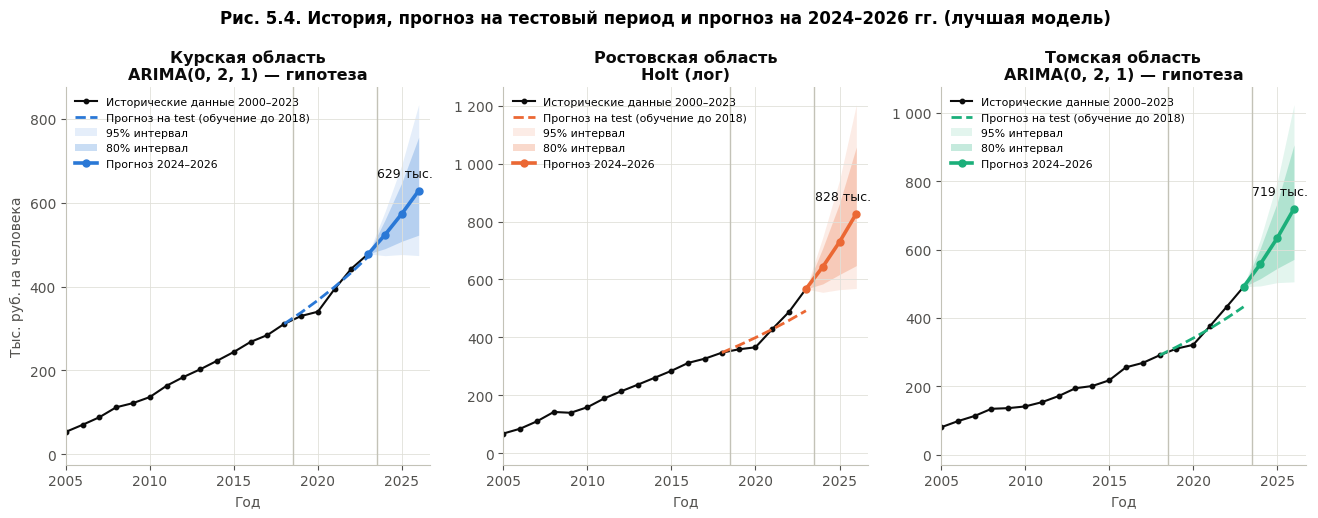

In [43]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.9))
for ax, r in zip(axes, REGIONS):
    y = W[r]; F = FUT[r]; c = REGION_COLOR[r]
    ax.plot(y.index, y, color=INK, marker='o', markersize=3.2, linewidth=1.5, label='Исторические данные 2000–2023')
    tf = test_fc[(r, BEST[r])]
    ax.plot([TRAIN_END] + TEST_YEARS, [y.loc[TRAIN_END]] + tf.tolist(), color=c, linestyle='--', linewidth=2,
            label=f'Прогноз на test (обучение до {TRAIN_END})')
    if 'нижн. 95%' in F:
        ax.fill_between([LAST_YEAR] + FUTURE_YEARS, [y.iloc[-1]] + F['нижн. 95%'].tolist(), [y.iloc[-1]] + F['верхн. 95%'].tolist(),
                        color=c, alpha=0.12, linewidth=0, label='95% интервал')
        ax.fill_between([LAST_YEAR] + FUTURE_YEARS, [y.iloc[-1]] + F['нижн. 80%'].tolist(), [y.iloc[-1]] + F['верхн. 80%'].tolist(),
                        color=c, alpha=0.25, linewidth=0, label='80% интервал')
    ax.plot([LAST_YEAR] + FUTURE_YEARS, [y.iloc[-1]] + F['прогноз'].tolist(), color=c, linewidth=2.6, marker='o', markersize=5,
            label='Прогноз 2024–2026')
    ax.annotate(f"{F['прогноз'].iloc[-1]/1000:,.0f} тыс.".replace(',', ' '), (FUTURE_YEARS[-1], F['прогноз'].iloc[-1]),
                textcoords='offset points', xytext=(-30, 10), fontsize=9, color=INK)
    ax.axvline(TRAIN_END + 0.5, color=AXIS, linewidth=1)
    ax.axvline(LAST_YEAR + 0.5, color=AXIS, linewidth=1)
    ax.set_xlim(2005, FUTURE_YEARS[-1] + 0.7)
    thousands(ax)
    ax.set_title(f'{r}\n{model_label(BEST[r], r)}')
    ax.set_xlabel('Год')
    ax.legend(loc='upper left', fontsize=7.8)
axes[0].set_ylabel('Тыс. руб. на человека')
fig.suptitle('Рис. 5.4. История, прогноз на тестовый период и прогноз на 2024–2026 гг. (лучшая модель)', fontweight='bold', y=1.04)
save_fig(fig, '16_final_forecasts')
plt.show()

## 5.6. Выводы по этапу 5
Выводы записаны после выполнения ячеек выше и опираются на таблицы `test_metrics`, `stability_expanding`, `backtest_all_models` и рис. 5.1–5.4.

**1. Все статистические модели существенно лучше наивного бейзлайна.**
* Наивный прогноз даёт MAPE 19,0–22,4%: он игнорирует рост, и к 2023 г. ошибается на 35–41%.
* Лучшие модели дают MAPE 3,0–6,5%, их RMSE составляет всего 13–32% от RMSE наивного прогноза.
* Значит, прогноз содержательный: модели улавливают трендовую динамику, а не просто повторяют последнее значение.

**2. Лучшая модель по региону (минимальный MAPE на тесте 2019–2023):**

| Регион (кластер) | Лучшая модель | MAPE | RMSE, тыс. руб. | Ближайший конкурент |
|---|---|---|---|---|
| Курская (1, устойчивый рост) | ARIMA(0,2,1) на ln (гипотеза) | 3,04% | 13,9 | Holt (лог): 3,04%, 13,9 тыс. — фактически ничья |
| Ростовская (2, со спадами) | Holt (лог) | 6,48% | 39,6 | ARIMA(0,2,1): 6,70% |
| Томская (3, замедленный рост) | ARIMA(0,2,1) на ln (гипотеза = авто) | 5,79% | 31,5 | Holt (лог): 6,30% |

**Почему так:**
* Holt (лог) и ARIMA(0,2,1) почти совпадают, потому что это близкие модели. Метод Holt эквивалентен ARIMA(0,2,2), а при α = 1
  (так оценилось у Курской и Ростовской) прогноз Holt строится от последнего наблюдения с адаптивным темпом, как ARIMA(0,2,1).
  Обе модели экстраполируют **последний сглаженный темп роста**, а это именно то, что нужно для ряда с меняющимся темпом (I(2)).
* **Holt на уровнях заметно хуже** (MAPE 6,0 / 9,9 / 11,1%). У Ростовской и Томской β = 0, то есть тренд фиксирован на
  +18,5 и +15,5 тыс. руб. в год, и линейная экстраполяция рублёвого прироста недооценивает экспоненциальный номинальный рост.
  **Переход к логарифмам важнее, чем выбор между Holt и ARIMA.**
* **Гипотеза против автоподбора.** Для Ростовской и Томской автоподбор по AICc выбрал ту же ARIMA(0,2,1), что и анализ ACF/PACF.
  Для Курской автоподбор выбрал более простую ARIMA(0,2,0): коэффициент θ₁ = −0,35 незначим (p = 0,27), разница AICc всего 1,15.
  Однако гипотеза (0,2,1) точнее и на тесте (3,04% против 3,63%), и в бэктесте (3,94% против 4,21%). На 17 точках после двойного
  дифференцирования AICc слабо различает близкие модели.
* **Проверка d = 1.** ARIMA на ln с d = 1 и дрейфом даёт MAPE 14,9 / 17,7 / 8,6%. Дрейф 16–19% в год «выучен» на высоком
  росте начала 2000-х и сильно завышает прогноз. Это подтверждает выбор d = 2.
* **Почему у регионов разная точность.** Курская область растёт ровнее всех, её прирост 2023 г. (7,9%) близок к тренду, поэтому
  к 2023 г. ошибка всего 1,4%. У Ростовской и Томской в 2022–2023 гг. было ускорение (+13,9% и +16,1%; +15,1% и +13,4%),
  которое нельзя было предвидеть из 2018 г. Поэтому к 2023 г. модели недооценивают уровень на 13,3% и 11,9%.

**3. Устойчивость (расширяющееся окно):**
* **Курская**: MAPE на 1 шаг за 2019–2023 гг. 4,2%, это *выше*, чем на фиксированном разбиении (3,0%). Хороший результат
  фиксированного разбиения отчасти случаен: прогноз из 2018 г. переоценил 2020 г. (−8,0%), а скачок 2021–2023 гг. это компенсировал.
  Пошаговый прогноз не предвидел скачок 2021 г. (+10,0%).
* **Ростовская и Томская**: 5,4% против 6,5% и 3,7% против 5,8%. При ежегодном обновлении данных модель успевает подхватить
  ускорение 2021–2023 гг., а на фиксированном разбиении ошибка накапливается с горизонтом.
* **Ошибка растёт с горизонтом**: от h = 1 до h = 3 она увеличивается с 3,9% до 12,5% (Курская), с 7,2% до 22,9% (Ростовская)
  и с 4,8% до 15,0% (Томская). Если не учитывать кризис 2009–2010 гг. (цели 2014–2023), ошибка на h = 3 равна 8,7 / 14,1 / 10,5%.
  Это ориентир надёжности прогноза на 2026 г.
* **Накопление данных помогает, кроме кризисов.** MAPE на 1 шаг снизился с 5,7% (2008–2013) до 1,6% (2014–2018) у Курской и
  с 12,3% до 2,8% у Ростовской. У Томской улучшения нет (5,0% → 5,7%) из-за «нефтяной пилы» 2014–2017 гг. Если исключить
  2009–2010 гг., MAPE на 1 шаг составляет 3,2 / 3,9 / 4,1%.
* **Бэктест всех моделей** (h = 1, 2008–2023 гг.) показывает, что ARIMA(0,2,1) самая устойчивая:
  * для Ростовской 5,24% против 7,17% у Holt (лог);
  * для Томской 4,80% против 6,54%;
  * для Курской 3,94%; Holt на уровнях здесь чуть точнее (3,71%), но за 2019–2023 гг. проигрывает (4,72% против 4,20%).

  Holt (лог) хуже после кризисов: на коротких выборках его параметры вырождаются (подробности на этапе 6). Для Ростовской
  победитель теста Holt (лог) и ARIMA(0,2,1) дают почти одинаковый прогноз на 2026 г. (827,6 и 832,8 тыс. руб., разница 0,6%),
  поэтому выбор модели не меняет выводов.
* Наивный прогноз проигрывает и в бэктесте: MAPE на 1 шаг 8,6–9,9%, это примерно средний годовой прирост.

**4. Прогноз на 2024–2026 гг. (лучшая модель):**
* Курская область: 523,8 → 573,9 → 628,9 тыс. руб. (+9,6% в год; 80% интервал на 2026 г.: 523–757 тыс.).
* Ростовская область: 643,2 → 729,6 → 827,6 тыс. (+13,4% в год; 648–1057 тыс.).
* Томская область: 557,6 → 633,4 → 719,4 тыс. (+13,6% в год; 571–906 тыс.).

Модели продолжают последний темп роста. У Курской он ниже, потому что в 2023 г. её рост замедлился до 7,9%. У Ростовской и
Томской выше, потому что в 2023 г. было 16,1% и 13,4%. Интервалы быстро расширяются: при d = 2 неопределённость самого темпа роста
накапливается, поэтому прогноз на 2026 г. следует рассматривать как сценарный ориентир.

---
# Этап 6. Анализ ошибок лучшей модели
Анализируем ошибки прогноза **на 1 год вперёд** из расширяющегося окна за 2008–2023 гг. (16 точек на регион). На фиксированном
тесте всего 5 точек, и «топ-5» совпал бы со всем тестом, а длинный бэктест захватывает все кризисы периода. Знак ошибки:
**ошибка = факт − прогноз**. Отрицательная ошибка значит, что модель переоценила потребление, положительная — недооценила.

In [44]:
EVENTS = {
    2008: 'Начало мирового финансового кризиса (осень 2008), обвал цен на нефть во II полугодии',
    2009: 'Мировой финансовый кризис: спад ВВП РФ на 7,8%, девальвация рубля, рост безработицы, сокращение кредитования',
    2010: 'Посткризисное восстановление; трендовая компонента моделей ещё «помнит» и докризисный рост, и провал 2009 г.',
    2011: 'Восстановительный рост доходов и потребления',
    2012: 'Стабилизация, замедление инфляции',
    2013: 'Замедление экономики накануне кризиса 2014 г.',
    2014: 'Падение цен на нефть, первые санкции, девальвация рубля (декабрь 2014)',
    2015: 'Спад реальных доходов, инфляция 12,9%, сокращение потребительского спроса',
    2016: 'Стагнация реальных доходов, замедление инфляции до 5,4%',
    2017: 'Рекордно низкая инфляция (2,5%) — замедление номинального роста',
    2018: 'Умеренный рост доходов',
    2019: 'Повышение НДС до 20%, слабый рост реальных доходов',
    2020: 'Пандемия COVID-19: ограничения, падение потребления услуг, рост сбережений',
    2021: 'Восстановление после пандемии, отложенный спрос, ускорение инфляции до 8,4%',
    2022: 'Санкционное давление, инфляция 11,9%, перестройка импорта',
    2023: 'Рост зарплат на фоне дефицита кадров, бюджетные выплаты, ослабление рубля, инфляция 7,4%',
}

top_tabs = {}
for r in REGIONS:
    e1 = BT[r][BT[r].h == 1].copy()
    top = e1.reindex(e1['APE, %'].sort_values(ascending=False).index).head(5)
    top['направление'] = np.where(top['ошибка, руб.'] < 0, 'переоценка', 'недооценка')
    top['событие'] = top['год'].map(EVENTS)
    top = top[['год', 'размер train', 'факт', 'прогноз', 'ошибка, руб.', 'ошибка, %', 'направление', 'событие']]
    top_tabs[r] = top
    top.to_csv(TAB_DIR / f'top5_errors_{REGIONS.index(r)+1}.csv', index=False, encoding='utf-8-sig')
    print(f'\n{r} — {model_label(BEST[r], r)}: топ-5 ошибок прогноза на 1 год')
    display(top.round(1))
RESULTS['top5'] = {r: top_tabs[r].to_dict(orient='records') for r in REGIONS}


Курская область — ARIMA(0, 2, 1) — гипотеза: топ-5 ошибок прогноза на 1 год


,год,размер train,факт,прогноз,"ошибка, руб.","ошибка, %",направление,событие
3,2009,9,121783.8,142939.6,-21155.8,-17.4,переоценка,"Мировой финансовый кризис: спад ВВП РФ на 7,8%, девальвация рубля, рост безработицы, сокращение кредитования"
39,2021,21,394356.6,354867.8,39488.8,10.0,недооценка,"Восстановление после пандемии, отложенный спрос, ускорение инфляции до 8,4%"
9,2011,11,163201.7,152467.4,10734.3,6.6,недооценка,Восстановительный рост доходов и потребления
12,2012,12,184039.6,191554.2,-7514.6,-4.1,переоценка,"Стабилизация, замедление инфляции"
15,2013,13,202499.7,210698.1,-8198.4,-4.0,переоценка,Замедление экономики накануне кризиса 2014 г.



Ростовская область — Holt (лог): топ-5 ошибок прогноза на 1 год


,год,размер train,факт,прогноз,"ошибка, руб.","ошибка, %",направление,событие
6,2010,10,158695.2,207566.7,-48871.5,-30.8,переоценка,"Посткризисное восстановление; трендовая компонента моделей ещё «помнит» и докризисный рост, и провал 2009 г."
3,2009,9,139375.1,180115.8,-40740.7,-29.2,переоценка,"Мировой финансовый кризис: спад ВВП РФ на 7,8%, девальвация рубля, рост безработицы, сокращение кредитования"
39,2021,21,428455.1,379706.3,48748.8,11.4,недооценка,"Восстановление после пандемии, отложенный спрос, ускорение инфляции до 8,4%"
27,2017,17,326549.5,344116.1,-17566.6,-5.4,переоценка,"Рекордно низкая инфляция (2,5%) — замедление номинального роста"
15,2013,13,236573.4,246950.2,-10376.8,-4.4,переоценка,Замедление экономики накануне кризиса 2014 г.



Томская область — ARIMA(0, 2, 1) — гипотеза: топ-5 ошибок прогноза на 1 год


,год,размер train,факт,прогноз,"ошибка, руб.","ошибка, %",направление,событие
3,2009,9,136650.2,159650.0,-22999.8,-16.8,переоценка,"Мировой финансовый кризис: спад ВВП РФ на 7,8%, девальвация рубля, рост безработицы, сокращение кредитования"
39,2021,21,376287.7,337545.8,38741.9,10.3,недооценка,"Восстановление после пандемии, отложенный спрос, ускорение инфляции до 8,4%"
18,2014,14,201309.7,219400.3,-18090.6,-9.0,переоценка,"Падение цен на нефть, первые санкции, девальвация рубля (декабрь 2014)"
27,2017,17,268739.5,292448.7,-23709.2,-8.8,переоценка,"Рекордно низкая инфляция (2,5%) — замедление номинального роста"
24,2016,16,255898.1,234230.8,21667.3,8.5,недооценка,"Стагнация реальных доходов, замедление инфляции до 5,4%"


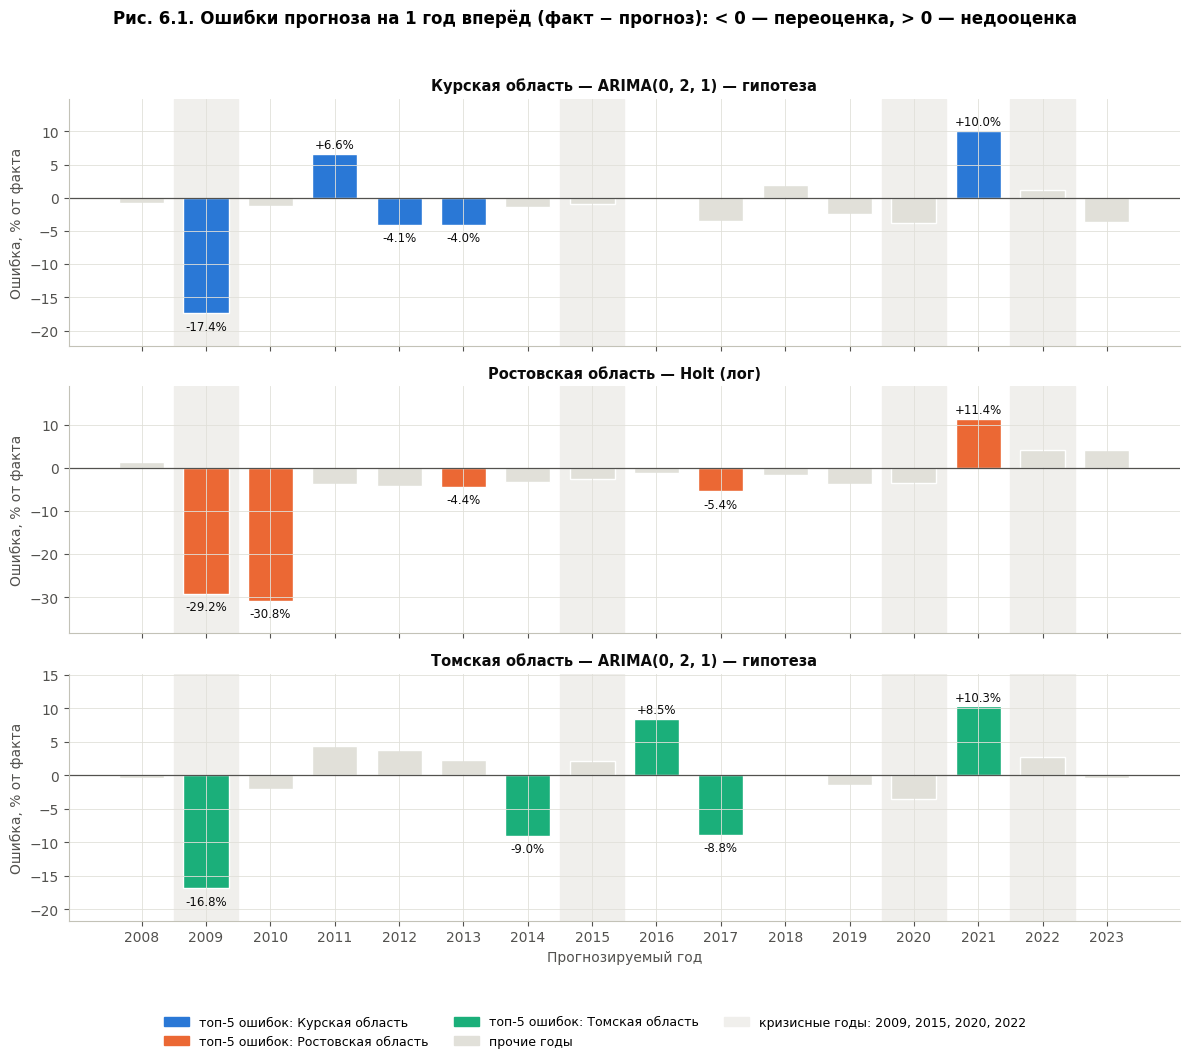

In [45]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, r in zip(axes, REGIONS):
    e1 = BT[r][BT[r].h == 1]
    top_years = set(top_tabs[r]['год'])
    for (a, b) in [(2008.5, 2009.5), (2014.5, 2015.5), (2019.5, 2020.5), (2021.5, 2022.5)]:
        ax.axvspan(a, b, color=BAND, zorder=0)
    cols = [REGION_COLOR[r] if y in top_years else GRID for y in e1['год']]
    bars = ax.bar(e1['год'], e1['ошибка, %'], color=cols, width=0.7, edgecolor='white')
    for y, v in zip(e1['год'], e1['ошибка, %']):
        if y in top_years:
            ax.annotate(f'{v:+.1f}%', (y, v), textcoords='offset points', xytext=(0, 4 if v > 0 else -12),
                        ha='center', fontsize=8.5, color=INK)
    ax.axhline(0, color=INK2, linewidth=0.9)
    ax.margins(y=0.18)
    ax.set_title(f'{r} — {model_label(BEST[r], r)}', fontsize=10.5)
    ax.set_ylabel('Ошибка, % от факта')
axes[-1].set_xticks(range(2008, 2024))
axes[-1].set_xlabel('Прогнозируемый год')
fig.legend(handles=[Patch(color=REGION_COLOR[r], label=f'топ-5 ошибок: {r}') for r in REGIONS] +
                   [Patch(color=GRID, label='прочие годы'), Patch(color=BAND, label='кризисные годы: 2009, 2015, 2020, 2022')],
           loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.05))
fig.suptitle('Рис. 6.1. Ошибки прогноза на 1 год вперёд (факт − прогноз): < 0 — переоценка, > 0 — недооценка',
             fontweight='bold', y=1.0)
fig.tight_layout(rect=(0, 0.03, 1, 0.98))
save_fig(fig, '17_errors_by_year')
plt.show()

In [46]:
# Ошибки на фиксированном тесте 2019–2023 (прогноз из 2018 г. на 1–5 лет): дополняют картину
fixed_err = []
for r in REGIONS:
    f = test_fc[(r, BEST[r])]
    for y in TEST_YEARS:
        a = W[r].loc[y]
        fixed_err.append({'регион': r, 'год': y, 'h': y - TRAIN_END, 'факт': a, 'прогноз': f.loc[y],
                          'ошибка, %': (a - f.loc[y]) / a * 100})
fixed_err = pd.DataFrame(fixed_err)
save_tab(fixed_err, 'fixed_test_errors', index=False)
display(fixed_err.pivot(index='год', columns='регион', values='ошибка, %')[REGIONS].round(2))

регион,Курская область,Ростовская область,Томская область
год,,,
2019,-2.50,-3.79,-1.47
2020,-8.04,-9.13,-6.05
2021,-1.24,0.16,1.89
2022,2.04,6.06,7.68
2023,1.35,13.28,11.87


### Гипотезы о причинах ошибок
Общая закономерность (рис. 6.1): **крупные ошибки сосредоточены в точках разворота делового цикла.** В кризисные годы модели
переоценивают потребление, потому что экстраполируют докризисный разгон. В годы восстановления (2011, 2016, 2021) недооценивают,
потому что экстраполируют провал. Одномерная модель не видит причин разворота, она лишь продолжает последний темп.

| Год | Регионы (ошибка) | Событие | Гипотеза о причине ошибки |
|---|---|---|---|
| **2009** | Курская −17,4%, Ростовская −29,2%, Томская −16,8% (топ-1–2 везде) | Мировой финансовый кризис: спад ВВП РФ на 7,8%, обвал нефти, девальвация, рост безработицы, сжатие кредитования | Модели, обученные на 2000–2008 гг. с номинальным ростом 18–30% в год, ждали роста на +28% / +27% / +18%. Фактически было +8,9% / −2,0% / +1,4%. Структурный разрыв невозможно предсказать по самому ряду. Сильнее всего ошиблись по Ростовской области: это регион кластера «рост с эпизодами спада» с единственным среди трёх номинальным падением. Вероятно, сказалась зависимость потребления от кредита, строительства и промышленности |
| **2010** | Ростовская −30,8% (топ-1) | Посткризисное восстановление | Это артефакт модели, а не экономики. На 10 точках (2000–2009) оптимальные по SSE параметры Holt выродились в α = β = 0, то есть в жёсткий тренд +23% в год, который не реагирует на спад 2009 г. Прогноз на 2010 г. оказался на 49% выше уровня 2009 г. ARIMA(0,2,1) в этой точке ошиблась менее чем на 4%. Отсюда вывод: на коротких рядах Holt неустойчив |
| **2011** | Курская +6,6% (недооценка) | Восстановительный рост доходов | После 11,8% в 2010 г. прирост ускорился до 19,8%: отложенный спрос и индексация доходов. Модель экстраполировала умеренный темп |
| **2012–2013** | Курская −4,1% и −4,0%; Ростовская 2013 −4,4% | Замедление экономики: рост ВВП снизился до 1,8% в 2013 г. | Модели продолжали ускорение 2011 г., а экономика уже замедлялась |
| **2014** | Томская −9,0% | Падение цен на нефть, санкции, девальвация | Прирост в Томской области упал с 13,3% до 3,3%, раньше и глубже, чем в среднем по РФ (6,7%). Гипотеза: нефтедобывающий регион первым ощутил падение нефтяных доходов |
| **2016** | Томская +8,5% (недооценка) | Стагнация реальных доходов, инфляция 5,4% | После слабых 2014–2015 гг. прирост скачком вырос до 17,5%. Скачок есть и по РФ в целом (+13,1% при инфляции 5,4%), то есть фактор общий. Гипотеза: восстановление нефтяных доходов при слабом рубле и, возможно, методические изменения в расчётах Росстата; это требует проверки |
| **2017** | Ростовская −5,4%, Томская −8,8% | Рекордно низкая инфляция (2,5%) | Модели продолжили ускорение 2016 г., а номинальный рост упал до 4,7–5,0% из-за дезинфляции. У Томской области отрицательная ACF₁ Δ²ln (−0,38) как раз означает, что ускорения обычно разворачиваются. MA-компонента учитывает это лишь частично |
| **2021** | Курская +10,0%, Ростовская +11,4%, Томская +10,3% (топ-2–3 везде) | Восстановление после пандемии, отложенный спрос, инфляция 8,4%, рост потребительского кредитования | После пандемийного 2020 г. (прирост 2,0–3,6%) модели ждали продолжения слабого роста, а фактически прирост составил 16–17%. Классическая недооценка в точке разворота |

**Почему 2020 и 2022 гг. не попали в топ-5.** В 2020 г. ошибка на 1 шаг умеренная (−3,5…−3,7%): рост замедлился уже в 2019 г.
(3,3–6,7%), и модели ждали немногого. Зато в прогнозе из 2018 г. на фиксированном тесте 2020 г. дал ошибку −6…−9%.
В 2022 г. номинальное потребление продолжило расти на 12–15% на фоне инфляции 11,9%, что близко к экстраполяции после 2021 г.
Поэтому ошибки не превышают 4,2%. Санкционный шок не снизил **номинальный** показатель; на реальном потреблении картина могла быть иной.

---
# Этап 7. Индивидуальные рекомендации
Ниже собраны числа, на которых основаны рекомендации: прогноз лучшей модели на 2024–2026 гг., интервалы, ожидаемая ошибка
на горизонте 3 года из бэктеста и положение региона относительно России.

In [47]:
rec_rows = {}
rf_cagr_18_23 = (rf.loc[2023] / rf.loc[2018]) ** (1 / 5) - 1          # среднегодовой номинальный рост по РФ, 2018–2023
for r in REGIONS:
    y = W[r]; F = FUT[r]
    g_18_23 = (y.loc[2023] / y.loc[2018]) ** (1 / 5) - 1
    rec_rows[r] = {
        'сценарий «темп 2018–2023» на 2026, тыс. руб.': y.loc[2023] * (1 + g_18_23) ** 3 / 1000,
        'нижн. 80% 2026: ср. годовой рост, %': ((F.loc[2026, 'нижн. 80%'] / y.loc[2023]) ** (1 / 3) - 1) * 100,
        'нижн. 80% 2024, тыс. руб.': F.loc[2024, 'нижн. 80%'] / 1000,
        'базовый прогноз 2026 к нижней границе 80%, %': (F.loc[2026, 'нижн. 80%'] / F.loc[2026, 'прогноз'] - 1) * 100,
        'ср. годовой рост РФ 2018–2023, %': rf_cagr_18_23 * 100,
        'отношение к РФ 2026 (если РФ растёт темпом 2018–2023)':
            (F.loc[2026, 'прогноз'] / (rf.loc[2023] * (1 + rf_cagr_18_23) ** 3)),
        'MAPE бэктеста h=3 (цели 2014–2023), %': stability.loc[r, 'MAPE h=3 (цели 2014–2023), %'],
        'факт 2023, тыс. руб.': y.loc[2023] / 1000,
        'прогноз 2024, тыс. руб.': F.loc[2024, 'прогноз'] / 1000,
        'прогноз 2026, тыс. руб.': F.loc[2026, 'прогноз'] / 1000,
        '80% интервал 2026, тыс. руб.': f"{F.loc[2026, 'нижн. 80%']/1000:.0f}–{F.loc[2026, 'верхн. 80%']/1000:.0f}",
        'рост 2023→2026, %': (F.loc[2026, 'прогноз'] / y.loc[2023] - 1) * 100,
        'ср. годовой рост прогноза, %': ((F.loc[2026, 'прогноз'] / y.loc[2023]) ** (1 / 3) - 1) * 100,
        'ср. годовой рост 2018–2023 (факт), %': ((y.loc[2023] / y.loc[2018]) ** (1 / 5) - 1) * 100,
        'нижняя граница 80% в 2026 к 2023, %': (F.loc[2026, 'нижн. 80%'] / y.loc[2023] - 1) * 100,
        'MAPE бэктеста h=3, %': stability.loc[r, 'MAPE h=3, %'],
        'отношение к РФ 2000': y.loc[2000] / rf.loc[2000],
        'отношение к РФ 2023': y.loc[2023] / rf.loc[2023],
        'прирост 2023, %': (y.loc[2023] / y.loc[2022] - 1) * 100,
        'прирост РФ 2023, %': (rf.loc[2023] / rf.loc[2022] - 1) * 100,
    }
rec_tab = pd.DataFrame(rec_rows)
save_tab(rec_tab, 'recommendation_numbers')
display(rec_tab.map(lambda v: round(float(v), 2) if isinstance(v, (float, np.floating)) else v))
RESULTS['rec_numbers'] = rec_tab.to_dict()

,Курская область,Ростовская область,Томская область
"сценарий «темп 2018–2023» на 2026, тыс. руб.",618.7,761.27,672.05
"нижн. 80% 2026: ср. годовой рост, %",3.03,4.53,5.18
"нижн. 80% 2024, тыс. руб.",490.52,584.4,514.9
"базовый прогноз 2026 к нижней границе 80%, %",-16.88,-21.74,-20.59
"ср. годовой рост РФ 2018–2023, %",9.84,9.84,9.84
отношение к РФ 2026 (если РФ растёт темпом 2018–2023),0.78,1.03,0.9
"MAPE бэктеста h=3 (цели 2014–2023), %",8.66,14.11,10.51
"факт 2023, тыс. руб.",478.03,567.03,490.98
"прогноз 2024, тыс. руб.",523.8,643.19,557.65
"прогноз 2026, тыс. руб.",628.9,827.56,719.37


### Курская область (кластер 1 «Устойчивый быстрый рост», ARIMA(0,2,1))
Прогноз на 2026 г.: **628,9 тыс. руб.** на человека (+31,6% к 2023 г., +9,6% в год), 80% интервал **523–757 тыс.**

1. **Базовый план и индексация услуг в натуральной форме.** Прогнозный темп +9,6% в год близок к собственному среднему за
   2018–2023 гг. (9,0%) и к среднероссийскому (9,8%). Рекомендуется закладывать в планы на 2024–2026 гг. ориентиры
   **524 / 574 / 629 тыс. руб.** на человека. Расходы на бесплатные для населения услуги (образование, здравоохранение) входят
   в фактическое конечное потребление; их стоит индексировать не ниже 9–10% в год, иначе их доля в потреблении будет падать.
2. **Стресс-сценарий для приграничного региона.** Нижняя граница 80% интервала на 2026 г. составляет 523 тыс. руб., то есть
   всего +9,4% за три года (≈3,0% в год, ниже инфляции) и на 16,9% ниже базового прогноза. Модель обучена на данных по 2023 г.
   включительно и не знает о событиях августа 2024 г. в приграничных районах области (боевые действия, эвакуация жителей).
   По масштабу это шок, сопоставимый с 2009 г., когда ошибка модели составила −17,4%. Для приграничных муниципалитетов
   рекомендуется считать нижнюю границу (490,5 тыс. в 2024 г., 523 тыс. в 2026 г.) основным, а не стрессовым сценарием и под
   разницу с базовым прогнозом (≈106 тыс. руб. на человека в 2026 г.) формировать резерв мер социальной поддержки.
3. **Контроль конвергенции и ежегодный пересчёт.** Область подтянулась с 0,63 до 0,79 среднероссийского уровня, но в 2023 г.
   росла медленнее России (7,9% против 12,6%). Если Россия сохранит темп 2018–2023 гг., прогноз даёт отношение 0,78 в 2026 г.,
   то есть сближение остановится. Целевой показатель — удержать отношение к РФ не ниже 0,79. Прогноз нужно пересчитывать ежегодно
   по мере выхода данных Росстата: ошибка модели на 1 год вперёд составляет 3,9%, а на 3 года 12,5%.

### Ростовская область (кластер 2 «Рост с эпизодами спада», Holt на логарифмах)
Прогноз на 2026 г.: **827,6 тыс. руб.** (+45,9% к 2023 г., +13,4% в год), 80% интервал **648–1057 тыс.**, самый широкий из трёх.

1. **Не принимать точечный прогноз за базовый план.** Модель продолжает всплеск 2023 г. (+16,1% при +12,6% по РФ), и прогнозный
   темп 13,4% в год выше собственного среднего за 2018–2023 гг. (10,3%). Ошибка бэктеста на 3 года наибольшая из трёх регионов:
   22,9% (14,1% без кризиса 2009 г.). Рекомендуется брать за базу консервативный сценарий с темпом 2018–2023 гг., то есть
   **761 тыс. руб. в 2026 г.**, а модельные 828 тыс. считать оптимистичным сценарием.
2. **Антикризисный буфер и «триггер» пересмотра.** Регион относится к кластеру, чувствительному к шокам: в 2009 г. потребление
   упало на 2,0% (единственное номинальное падение среди трёх регионов), а ошибки модели составили −29,2% (2009) и −30,8% (2010).
   Нижняя граница 80% интервала на 2026 г. равна 648 тыс. (+4,5% в год), это на 21,7% ниже точечного прогноза. Стресс-тест
   бюджета (НДФЛ, расходы на соцподдержку) стоит проводить на этом уровне. Если фактический годовой прирост окажется ниже 5%
   (как в 2009, 2017, 2019 и 2020 гг.), планирование нужно сразу переводить на стресс-сценарий.
3. **Подготовка потребительской инфраструктуры к выходу на среднероссийский уровень.** Отношение к РФ выросло с 0,77 (2000) до
   0,94 (2023). Если Россия сохранит темп 2018–2023 гг. (9,8% в год), по прогнозу область к 2026 г. превысит средний уровень
   (≈1,03). Номинальный спрос на душу вырастет на 46%, и под это стоит планировать развитие торговли, услуг и транспортной
   логистики. Для мониторинга лучше использовать вместе с Holt и ARIMA(0,2,1): она устойчивее после шоков (бэктест 5,2% против
   7,2%) и даёт почти тот же прогноз на 2026 г. (833 тыс.).

### Томская область (кластер 3 «Замедленный рост с высокой базы», ARIMA(0,2,1))
Прогноз на 2026 г.: **719,4 тыс. руб.** (+46,5% к 2023 г., +13,6% в год), 80% интервал **571–906 тыс.**

1. **Проверить, закончилось ли «сближение сверху».** С 2000 по 2023 г. отношение к РФ снизилось с 0,86 до 0,81. Прогноз +13,6%
   в год выше среднероссийского темпа 9,8%, и тогда отношение вырастет до ≈0,90 к 2026 г. Но этот прогноз продолжает ускорение
   2021–2023 гг. (17,0%, 15,1%, 13,4%). Критерий проверки: если в 2024 г. потребление окажется ниже 515 тыс. руб. (нижняя граница
   80% интервала), ускорение закончилось. Тогда базой надо считать сценарий с темпом 2018–2023 гг., **672 тыс. руб. в 2026 г.**
2. **Привязать прогноз к нефтяному сценарию.** Помимо 2009 и 2021 гг., крупнейшие ошибки модели приходятся на «нефтяную пилу»
   2014 (−9,0%), 2016 (+8,5%) и 2017 (−8,8%) гг. У Томской области самая сильная отрицательная автокорреляция изменений темпа
   (−0,38): ускорения здесь быстро сменяются замедлениями. В годы падения цен на нефть рекомендуется сдвигать план к нижней
   границе 80% интервала: 571 тыс. руб. в 2026 г., +5,2% в год. Это на 20,6% ниже точечного прогноза.
3. **Защитить долю образовательных и медицинских услуг.** В Томской области крупный университетский сектор, а бесплатные
   образовательные и медицинские услуги входят в фактическое конечное потребление. Чтобы их доля не снижалась, расходы на них
   должны расти не медленнее прогноза потребления: 13,6% в год в базовом сценарии и не менее 5,2% в стресс-сценарии.
   Отставание от этих темпов будет означать относительное сжатие социальной сферы.

---
# Этап 8. Выводы по проекту
### Результаты кластеризации
В анализ вошли 79 субъектов с полными рядами 2000–2023 гг. (исключены 6 субъектов с пропусками и 11 агрегатов, исправлена
одна аномалия). По пяти признакам динамики K-means при k = 3 выделил три типа регионов:
1. **«Устойчивый быстрый рост»** (45 регионов): CAGR 16,0%, ни одного года номинального спада, отношение к РФ выросло с 0,68 до 0,85.
2. **«Рост с эпизодами спада»** (18 регионов): CAGR 15,6%, у каждого есть год номинального падения (2009, 2015, 2019–2020),
   максимальная волатильность темпов (около 12 п.п.). В основном индустриальные и ресурсные регионы.
3. **«Замедленный рост с высокой базы»** (16 регионов): CAGR 14,2%, Москва, северные и сибирские регионы. Отношение к РФ
   снизилось с 1,15 до 0,94, это межрегиональная конвергенция.

Силуэт 0,32 говорит об умеренной структуре: это скорее типология на континууме, чем жёстко разделённые группы.

### Результаты прогнозирования
* Все три ряда в логарифмах интегрированы порядка 2: темп роста сам имеет тренд из-за дезинфляции 2000-х.
  Поэтому лучшие модели — те, что экстраполируют последний сглаженный темп: **ARIMA(0,2,1) на ln** для Курской
  (кластер 1, MAPE 3,0%) и Томской (кластер 3, 5,8%) областей и **Holt на ln** для Ростовской (кластер 2, 6,5%, с ARIMA
  почти вровень).
* В бэктесте с расширяющимся окном **ARIMA(0,2,1) оказалась наиболее устойчивой моделью для всех трёх типов.**
* Все модели многократно лучше наивного прогноза (MAPE 19–22%). Решающим оказалось логарифмирование: Holt на рублях
  ошибается в 1,5–2 раза сильнее.
* **Точность совпадает с типом кластера**: самый гладкий ряд (кластер 1) прогнозируется точнее всего, а ряд из
  «шокового» кластера 2 хуже всего (ошибка на 3 года 22,9% против 12,5% у Курской).

### Что влияет на точность
1. **Развороты делового цикла и шоки**: 2009 г. (ошибка до −29%) и 2021 г. (+10–11%) — крупнейшие ошибки во всех регионах.
2. **Волатильность, присущая типу региона**: σ цикла 3,8 п.п. у Ростовской против 2,6 у Курской.
3. **Горизонт прогноза**: MAPE 4–7% на 1 год против 12–23% на 3 года.
4. **Длина выборки**: на 8–10 точках Holt вырождается (α = β = 0), отсюда ошибка −30,8% в 2010 г.
5. **Номинальные цены**: колебания инфляции (2,5% в 2017 г., 11,9% в 2022 г.) меняют номинальный рост независимо от реального потребления.

### Ограничения исследования
* **Модели одномерные.** Они не учитывают инфляцию, доходы, цены на нефть, ключевую ставку, бюджетные выплаты и миграцию,
  поэтому не могут предсказать развороты, только отреагировать на них с опозданием в год.
* **Данные номинальные.** Рост показателя смешивает реальное потребление и инфляцию, поэтому выводы об уровне жизни требуют дефлирования.
* **Короткие ряды.** 24 годовые точки, на обучении 19, на тесте всего 5. Выбор «лучшей» модели неустойчив: у Курской Holt и
  ARIMA различаются в третьем знаке MAPE. Тесты ADF и KPSS на таком объёме маломощны.
* **Интервалы прогноза** предполагают нормальные ошибки и отсутствие структурных сдвигов. В годы шоков (как 2009 и 2021)
  фактическая неопределённость выше расчётной.
* **События после 2023 г.** в данных не отражены: например, ситуация в приграничных районах Курской области с августа 2024 г.
  Прогноз на 2024–2026 гг. условен.
* **Кластеризация** по агрегированным признакам зависит от нескольких кризисных лет и умеренно устойчива (ARI с методом Уорда 0,54).

### Как улучшить результат
* Дефлировать ряды региональными ИПЦ и прогнозировать реальное потребление отдельно от инфляции.
* Добавить внешние регрессоры (ARIMAX, регрессия с ARIMA-ошибками): доходы, зарплаты, ИПЦ, цену нефти Urals, ключевую ставку.
  В сценарном режиме это позволит учитывать развороты.
* Использовать информацию всего кластера: панельные или иерархические модели и «глобальные» модели, обученные на всех
  79 регионах. Это компенсирует короткие ряды.
* Добавить фиктивные переменные структурных сдвигов (2009, 2020) и ансамбль Holt + ARIMA для снижения модельного риска.
* Перейти к более частым данным (квартальный оборот розничной торговли и платных услуг), чтобы увеличить число наблюдений.
* Кластеризовать траектории напрямую (DTW, k-shape) и проверить устойчивость кластеров бутстрепом.

In [48]:
# Сохраняем ключевые результаты для отчёта
with open('results.json', 'w', encoding='utf-8') as fh:
    json.dump(to_py(RESULTS), fh, ensure_ascii=False, indent=1, default=str)
print('Сохранено: results.json; графиков:', len(list(FIG_DIR.glob('*.png'))), '; таблиц:', len(list(TAB_DIR.glob('*.csv'))))

Сохранено: results.json; графиков: 19 ; таблиц: 29
